# Curvature Analysis — MUC2 Long PTS
## Glycosylated vs Non-glycosylated

In [172]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

base       = "/home/computer2/analysis_simulations/analysis/radius_of_curvature/"
output_dir = "/home/computer2/analysis_simulations/analysis/radius_of_curvature/plots"
os.makedirs(output_dir, exist_ok=True)

RES_OFFSET = 1377
CLR_GLY    = "#2E86AB"
CLR_NOG    = "#A23B72"

print("Ready. Output:", output_dir)

Ready. Output: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots


In [173]:
# Per-frame RMS curvature (kappa_rms per frame)
gly_frame = np.genfromtxt(base + "bending_angle_perframe_glycans.dat",   comments="#")
nog_frame = np.genfromtxt(base + "bending_angle_perframe_noglycans.dat", comments="#")

# Per-residue curvature profile (mean ± SE across all frames)
gly_prof  = np.genfromtxt(base + "curvature_profile_glycans.dat",   comments="#")
nog_prof  = np.genfromtxt(base + "curvature_profile_noglycans.dat", comments="#")
comp_prof = np.genfromtxt(base + "curvature_profile_comparison.dat",comments="#")

res_idx = gly_prof[:, 0].astype(int) + RES_OFFSET

# Glycan attachment sites (O-glycosylated residues in MUC2 numbering)
GLYCAN_RES = np.array([
    1379, 1383, 1386, 1389, 1393, 1397, 1402, 1406, 1409, 1412,
    1416, 1420, 1425, 1429, 1432, 1435, 1439, 1443, 1448, 1452,
    1455, 1458, 1462, 1466, 1471, 1475, 1478, 1481, 1485, 1489
])

def mark_glycans(ax, ymax_frac=0.97, color="#F39C12", alpha=0.35):
    """Draw vertical dashed lines at every glycan attachment site."""
    ylim = ax.get_ylim()
    yspan = ylim[1] - ylim[0]
    for r in GLYCAN_RES:
        ax.axvline(r, color=color, linewidth=0.8, linestyle="--", alpha=alpha, zorder=1)
    # Add a single legend entry for all glycan lines
    ax.axvline(GLYCAN_RES[0], color=color, linewidth=0.8, linestyle="--",
               alpha=alpha+0.2, label="Glycan site", zorder=1)

print(f"Per-frame glycans   : {len(gly_frame)} frames")
print(f"Per-frame noglycans : {len(nog_frame)} frames")
print(f"Per-residue sites   : {len(res_idx)}")
print(f"Glycan attachment sites: {len(GLYCAN_RES)}")
print()
print("Summary statistics (deg):")
print(f"  Glycosylated     mean={gly_frame[:,2].mean():.2f}  std={gly_frame[:,2].std():.2f}")
print(f"  Non-glycosylated mean={nog_frame[:,2].mean():.2f}  std={nog_frame[:,2].std():.2f}")

Per-frame glycans   : 2381 frames
Per-frame noglycans : 2381 frames
Per-residue sites   : 113
Glycan attachment sites: 30

Summary statistics (deg):
  Glycosylated     mean=121.75  std=0.95
  Non-glycosylated mean=116.85  std=1.24


## Figure 1 — Per-Frame RMS Bending Angle Distribution

Shows how much the chain bends on average across all residues, for every simulation frame.
**kappa_rms** = √(mean of θ²) where θ(i) = angle between consecutive tangent vectors at each Cα.
Smaller kappa = straighter chain. Larger kappa = more curved chain.

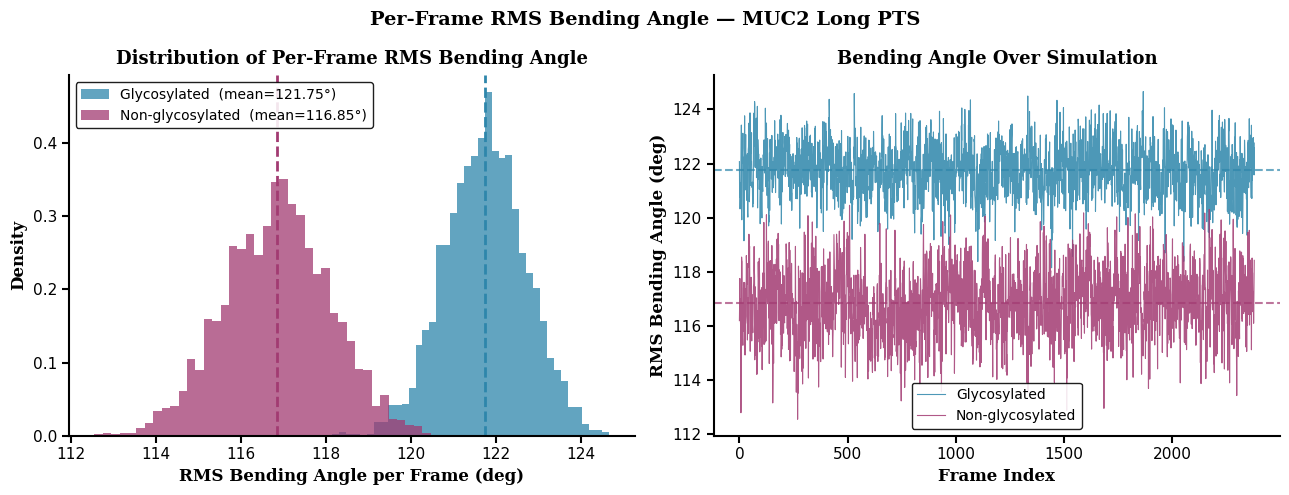

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/bending_angle_perframe.png


In [174]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=100)
fig.set_facecolor("white")

ax = axes[0]
ax.hist(gly_frame[:, 2], bins=40, color=CLR_GLY, alpha=0.75, density=True,
        label=f"Glycosylated  (mean={gly_frame[:,2].mean():.2f}°)")
ax.hist(nog_frame[:, 2], bins=40, color=CLR_NOG, alpha=0.75, density=True,
        label=f"Non-glycosylated  (mean={nog_frame[:,2].mean():.2f}°)")
ax.axvline(gly_frame[:, 2].mean(), color=CLR_GLY, linewidth=2, linestyle="--")
ax.axvline(nog_frame[:, 2].mean(), color=CLR_NOG, linewidth=2, linestyle="--")
ax.set_xlabel("RMS Bending Angle per Frame (deg)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Density", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Distribution of Per-Frame RMS Bending Angle", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold", pad=8)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

ax = axes[1]
ax.plot(gly_frame[:, 0], gly_frame[:, 2], color=CLR_GLY, linewidth=0.8,
        alpha=0.85, label="Glycosylated")
ax.plot(nog_frame[:, 0], nog_frame[:, 2], color=CLR_NOG, linewidth=0.8,
        alpha=0.85, label="Non-glycosylated")
ax.axhline(gly_frame[:, 2].mean(), color=CLR_GLY, linewidth=1.5, linestyle="--", alpha=0.7)
ax.axhline(nog_frame[:, 2].mean(), color=CLR_NOG, linewidth=1.5, linestyle="--", alpha=0.7)
ax.set_xlabel("Frame Index", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("RMS Bending Angle (deg)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Bending Angle Over Simulation", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold", pad=8)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

fig.suptitle("Per-Frame RMS Bending Angle — MUC2 Long PTS",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
out = os.path.join(output_dir, "bending_angle_perframe.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 2 — Per-Residue Curvature Profile (mean ± SE)

Shows where along the chain the bending is concentrated.
Each point = mean curvature at that Cα site averaged over all frames.
Error bars = standard error of the mean across frames.
**High κ at a residue** = that position consistently bends — a local hinge point.
**Low κ** = that residue stays straight across the simulation.

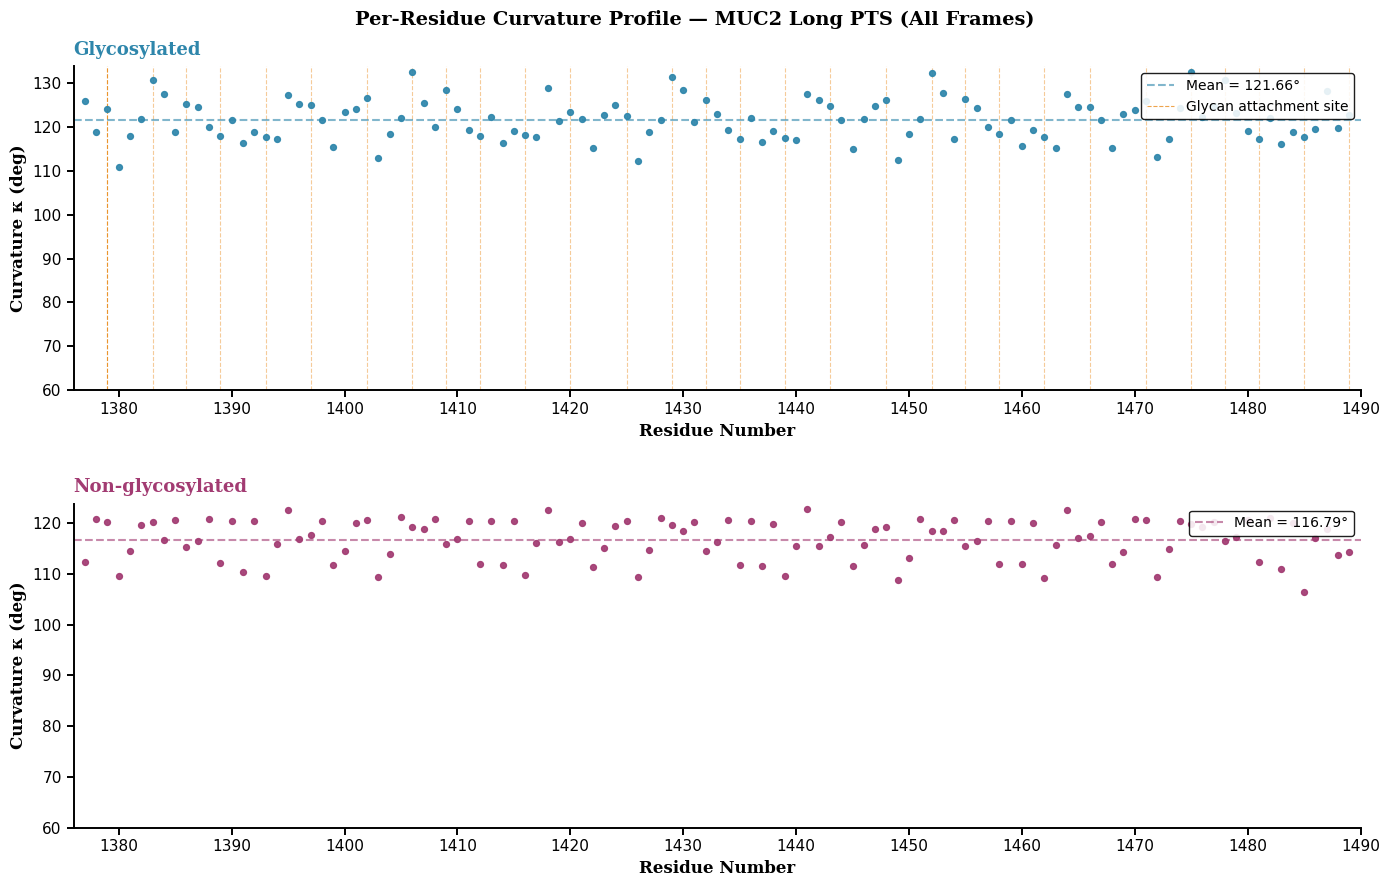

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_profile.png


In [175]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), dpi=100)
fig.set_facecolor("white")

for ax, prof, sys_label, sys_color, show_glycans in [
    (axes[0], gly_prof, "Glycosylated",    CLR_GLY, True),
    (axes[1], nog_prof, "Non-glycosylated", CLR_NOG, False),
]:
    kappa_deg = prof[:, 3]
    se_deg    = prof[:, 4]

    if show_glycans:
        for r in GLYCAN_RES:
            ax.axvline(r, color="#E67E00", linewidth=0.8, linestyle="--", alpha=0.4, zorder=1)

    ax.vlines(res_idx, kappa_deg - se_deg, kappa_deg + se_deg,
              color=sys_color, linewidth=0.8, alpha=0.35, zorder=2)
    ax.scatter(res_idx, kappa_deg, color=sys_color, s=18, zorder=4, alpha=0.92)
    ax.axhline(kappa_deg.mean(), color=sys_color, linewidth=1.5,
               linestyle="--", alpha=0.6, label=f"Mean = {kappa_deg.mean():.2f}°")

    if show_glycans:
        ax.axvline(GLYCAN_RES[0], color="#E67E00", linewidth=0.8, linestyle="--",
                   alpha=0.7, zorder=1, label="Glycan attachment site")

    ax.set_title(sys_label, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=8, loc="left")
    ax.set_ylabel("Curvature κ (deg)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlabel("Residue Number", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlim(res_idx[0] - 1, res_idx[-1] + 1)
    ax.set_ylim(60, None)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.legend(fontsize=10, framealpha=0.88, edgecolor="black", loc="upper right")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4)
    ax.spines["bottom"].set_linewidth(1.4)
    ax.tick_params(labelsize=11, length=5, width=1.4, direction="out")

fig.suptitle("Per-Residue Curvature Profile — MUC2 Long PTS (All Frames)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
plt.subplots_adjust(hspace=0.35)
out = os.path.join(output_dir, "curvature_profile.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 3 — Curvature Overlay and Delta Kappa

**Top:** Both systems overlaid for direct comparison.
**Bottom:** Delta kappa (glycosylated minus non-glycosylated) per residue.
Positive = glycosylated bends more at that site. Negative = non-glycosylated bends more.

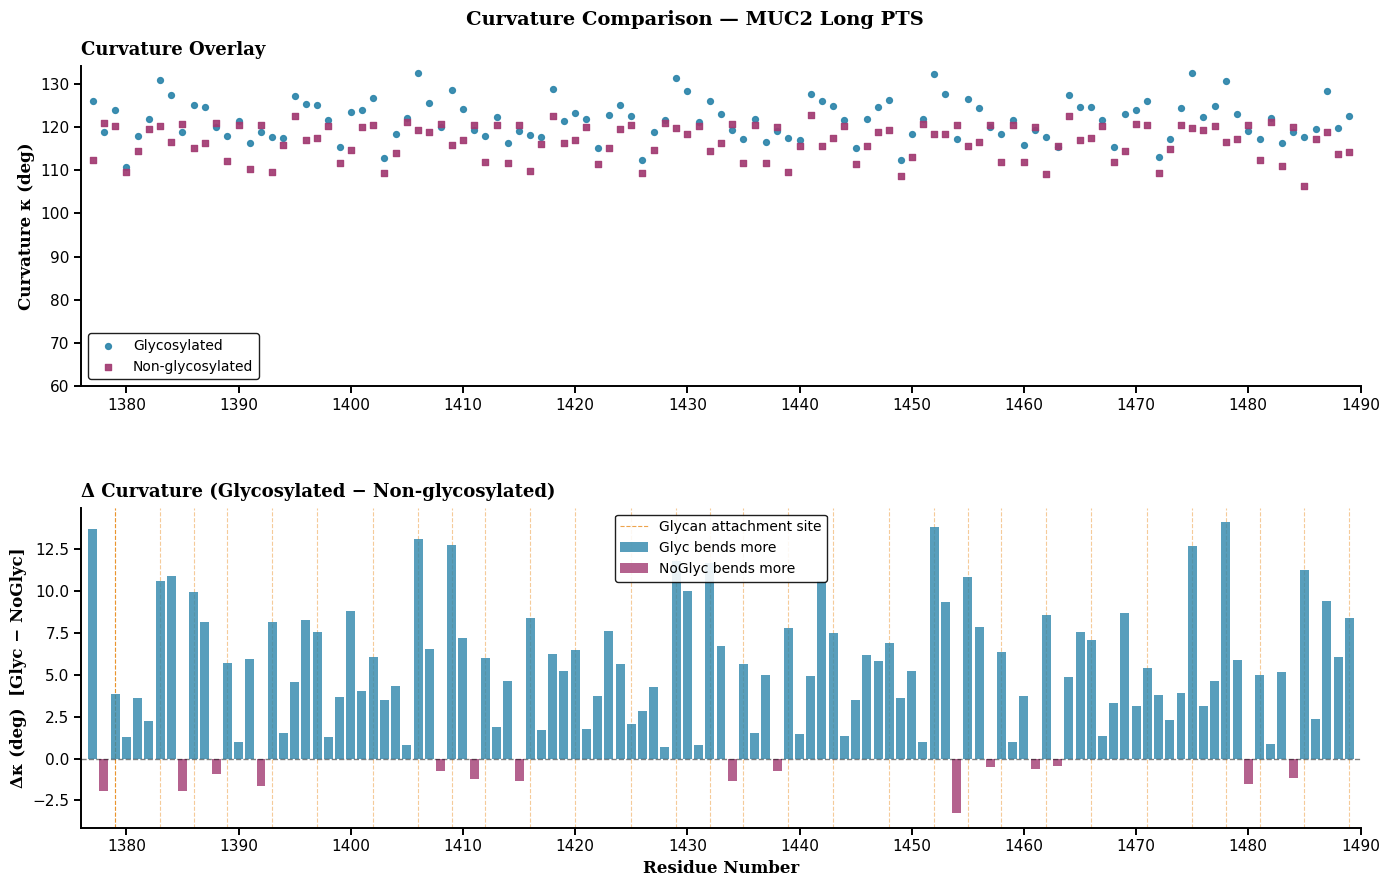

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_comparison.png


In [176]:
kappa_gly = comp_prof[:, 1];  se_gly = comp_prof[:, 2]
kappa_nog = comp_prof[:, 3];  se_nog = comp_prof[:, 4]
delta_k   = comp_prof[:, 5]
delta_deg = np.degrees(delta_k)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), dpi=100)
fig.set_facecolor("white")

# Top: overlay
ax = axes[0]
ax.vlines(res_idx, np.degrees(kappa_gly - se_gly), np.degrees(kappa_gly + se_gly),
          color=CLR_GLY, linewidth=0.8, alpha=0.3, zorder=2)
ax.vlines(res_idx, np.degrees(kappa_nog - se_nog), np.degrees(kappa_nog + se_nog),
          color=CLR_NOG, linewidth=0.8, alpha=0.3, zorder=2)
ax.scatter(res_idx, np.degrees(kappa_gly), color=CLR_GLY, s=18,
           zorder=4, alpha=0.92, label="Glycosylated")
ax.scatter(res_idx, np.degrees(kappa_nog), color=CLR_NOG, s=18,
           zorder=4, alpha=0.92, label="Non-glycosylated", marker="s")
ax.set_ylabel("Curvature κ (deg)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Curvature Overlay", fontsize=13, fontname="DejaVu Serif",
             fontweight="bold", pad=8, loc="left")
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_xlim(res_idx[0] - 1, res_idx[-1] + 1)
ax.set_ylim(60, None)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.4)
ax.spines["bottom"].set_linewidth(1.4)
ax.tick_params(labelsize=11, length=5, width=1.4, direction="out")

# Bottom: delta kappa
ax = axes[1]
for r in GLYCAN_RES:
    ax.axvline(r, color="#E67E00", linewidth=0.8, linestyle="--", alpha=0.4, zorder=1)
pos = delta_deg >= 0
neg = delta_deg < 0
ax.bar(res_idx[pos], delta_deg[pos], color=CLR_GLY, alpha=0.8,
       width=0.8, label="Glyc bends more", zorder=2)
ax.bar(res_idx[neg], delta_deg[neg], color=CLR_NOG, alpha=0.8,
       width=0.8, label="NoGlyc bends more", zorder=2)
ax.axhline(0, color="black", linewidth=1.0, linestyle="--", alpha=0.5)
ax.axvline(GLYCAN_RES[0], color="#E67E00", linewidth=0.8, linestyle="--",
           alpha=0.7, zorder=1, label="Glycan attachment site")
ax.set_ylabel("Δκ (deg)  [Glyc − NoGlyc]", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_xlabel("Residue Number", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Δ Curvature (Glycosylated − Non-glycosylated)", fontsize=13,
             fontname="DejaVu Serif", fontweight="bold", pad=8, loc="left")
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_xlim(res_idx[0] - 1, res_idx[-1] + 1)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.4)
ax.spines["bottom"].set_linewidth(1.4)
ax.tick_params(labelsize=11, length=5, width=1.4, direction="out")

fig.suptitle("Curvature Comparison — MUC2 Long PTS",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
plt.subplots_adjust(hspace=0.38)
out = os.path.join(output_dir, "curvature_comparison.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 4 — Overall Curvature Summary

Mean RMS bending angle across all frames and all residues, per system.
Error bars = std of the per-frame distribution.

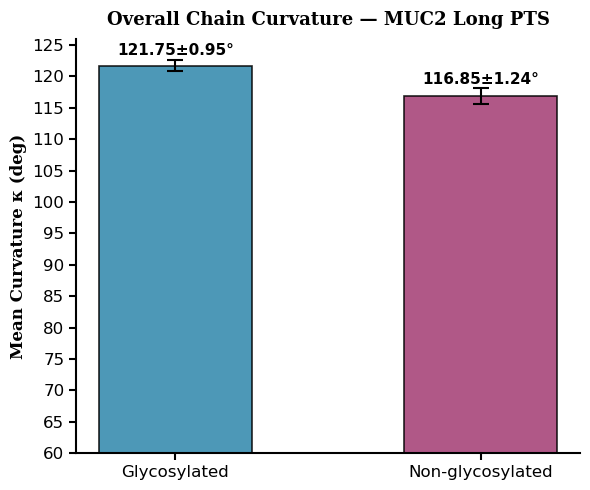

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_summary.png


In [177]:
fig, ax = plt.subplots(figsize=(6, 5), dpi=100)
fig.set_facecolor("white")

systems = ["Glycosylated", "Non-glycosylated"]
means   = [gly_frame[:, 2].mean(), nog_frame[:, 2].mean()]
stds    = [gly_frame[:, 2].std(),  nog_frame[:, 2].std()]
colors  = [CLR_GLY, CLR_NOG]

bars = ax.bar(systems, means, yerr=stds, color=colors, alpha=0.85,
              edgecolor="black", linewidth=1.2, width=0.5,
              error_kw=dict(elinewidth=1.5, capsize=6, capthick=1.5, ecolor="black"))

for bar, mean, std in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width()/2, mean + std + 0.3,
            f"{mean:.2f}±{std:.2f}°",
            ha="center", va="bottom", fontsize=11, fontweight="bold")

ax.set_ylabel("Mean Curvature κ (deg)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Overall Chain Curvature — MUC2 Long PTS",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=12, length=5, width=1.5, direction="out")
ax.set_ylim(60, max(means) + max(stds) + 3)
ax.yaxis.set_major_locator(ticker.MultipleLocator(5))

plt.tight_layout()
out = os.path.join(output_dir, "curvature_summary.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

---
## Three-System Comparison — Including Ext. Glycosylated

In [178]:
CLR_EXT  = "#F18F01"
base_ext = "/home/computer2/analysis_simulations/analysis/curvature_xglyc/"

ext_frame = np.genfromtxt(base_ext + "bending_angle_perframe_xglyc.dat", comments="#")
ext_prof  = np.genfromtxt(base_ext + "curvature_profile_xglyc.dat",      comments="#")

print(f"Per-frame ext_glycans : {len(ext_frame)} frames")
print(f"Per-residue ext_glycans: {len(ext_prof)} sites")
print()
print("Summary statistics (deg):")
print(f"  Glycosylated      mean={gly_frame[:,2].mean():.2f}  std={gly_frame[:,2].std():.2f}")
print(f"  Non-glycosylated  mean={nog_frame[:,2].mean():.2f}  std={nog_frame[:,2].std():.2f}")
print(f"  Ext. Glycosylated mean={ext_frame[:,2].mean():.2f}  std={ext_frame[:,2].std():.2f}")

Per-frame ext_glycans : 2381 frames
Per-residue ext_glycans: 113 sites

Summary statistics (deg):
  Glycosylated      mean=121.75  std=0.95
  Non-glycosylated  mean=116.85  std=1.24
  Ext. Glycosylated mean=123.11  std=0.84


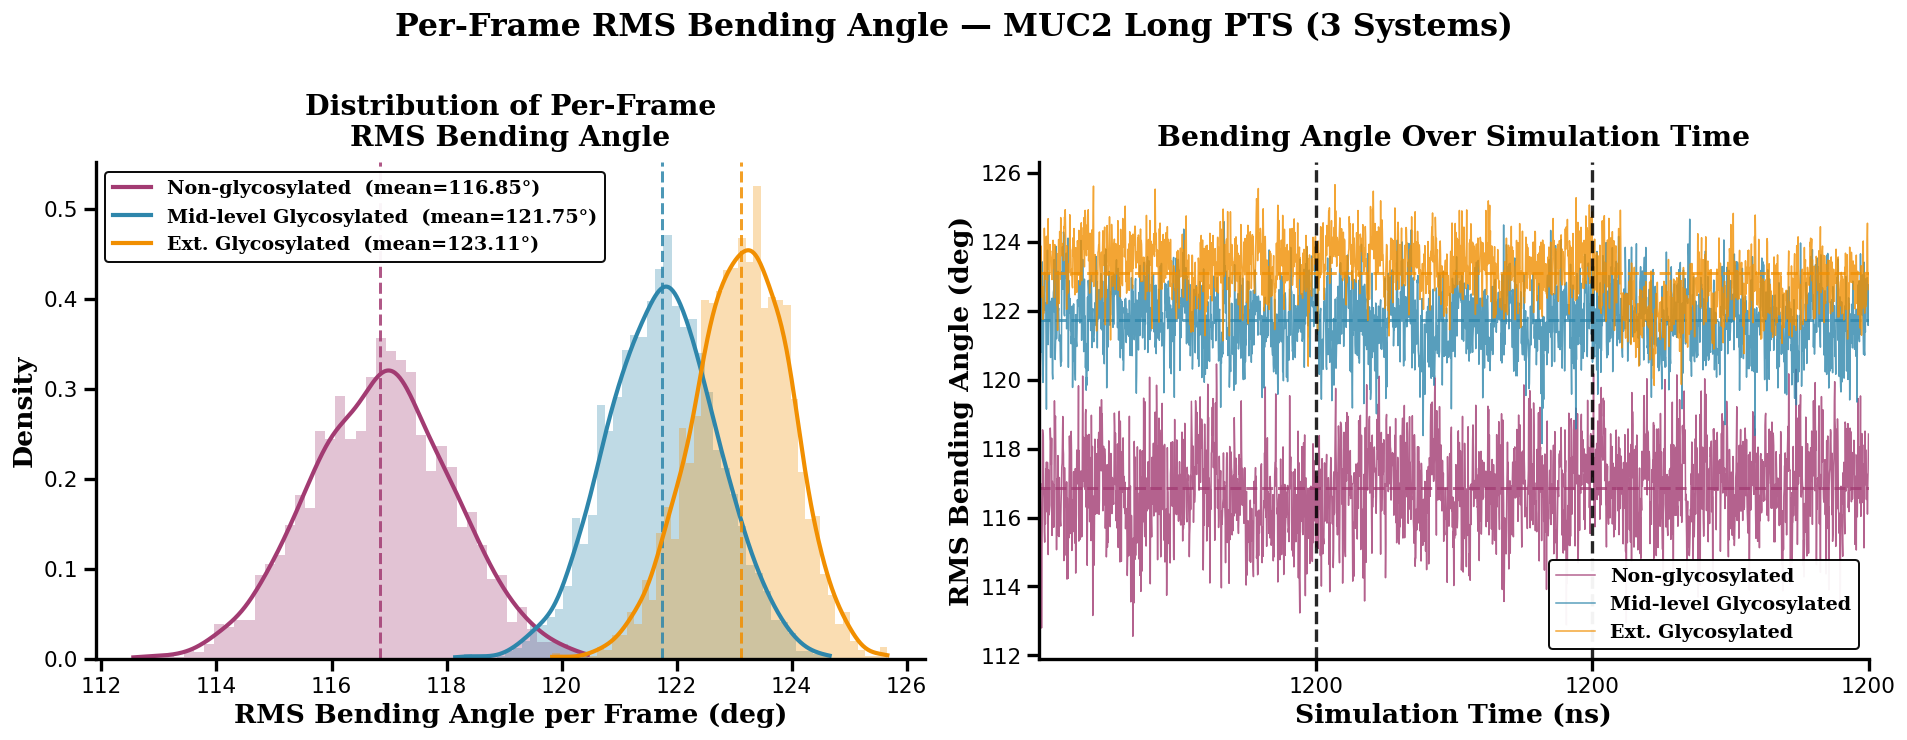

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/bending_angle_perframe_3sys.png


In [179]:
from scipy.stats import gaussian_kde

FRAME_DT_NS = 1.2
N_FRAMES    = 2381
time_ns     = np.arange(N_FRAMES) * FRAME_DT_NS
total_ns    = time_ns[-1]

seg      = total_ns / 3
tick_pos = [seg, 2*seg, total_ns]
line_pos = [seg, 2*seg]

sys_info = [
    (nog_frame, "Non-glycosylated",       CLR_NOG),
    (gly_frame, "Mid-level Glycosylated", CLR_GLY),
    (ext_frame, "Ext. Glycosylated",      CLR_EXT),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)
fig.set_facecolor("white")

ax = axes[0]
for frm, lbl, clr in sys_info:
    data = frm[:, 2]
    ax.hist(data, bins=45, color=clr, alpha=0.30, density=True, edgecolor="none")
    kde = gaussian_kde(data, bw_method=0.25)
    x_r = np.linspace(data.min(), data.max(), 400)
    ax.plot(x_r, kde(x_r), color=clr, linewidth=2.5,
            label=f"{lbl}  (mean={data.mean():.2f}\u00b0)")
    ax.axvline(data.mean(), color=clr, linewidth=1.8, linestyle="--", alpha=0.85)
ax.set_xlabel("RMS Bending Angle per Frame (deg)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Density", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Distribution of Per-Frame\nRMS Bending Angle", fontsize=17, fontname="DejaVu Serif", fontweight="bold", pad=10)
leg = ax.legend(fontsize=11.5, framealpha=0.95, edgecolor="black", prop={"family":"DejaVu Serif","size":11.5,"weight":"bold"})
leg.get_frame().set_linewidth(1.2)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=13, length=7, width=2.0, direction="out")

ax = axes[1]
for frm, lbl, clr in sys_info:
    n = min(len(frm), N_FRAMES)
    ax.plot(time_ns[:n], frm[:n, 2], color=clr, linewidth=0.9, alpha=0.80, label=lbl)
    ax.axhline(frm[:n, 2].mean(), color=clr, linewidth=1.8, linestyle="--", alpha=0.75)
for t in line_pos:
    ax.axvline(t, color="black", linewidth=2.0, linestyle="--", alpha=0.85, zorder=5)

ax.set_xlim(0, total_ns)
ax.xaxis.set_major_locator(ticker.NullLocator())
ax.xaxis.set_minor_locator(ticker.NullLocator())
ax.set_xticks(tick_pos)
ax.set_xticklabels(['1200', '1200', '1200'], fontsize=13)
ax.set_xlabel("Simulation Time (ns)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("RMS Bending Angle (deg)", fontsize=16, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Bending Angle Over Simulation Time", fontsize=17, fontname="DejaVu Serif", fontweight="bold", pad=10)
leg = ax.legend(fontsize=11.5, framealpha=0.95, edgecolor="black", prop={"family":"DejaVu Serif","size":11.5,"weight":"bold"})
leg.get_frame().set_linewidth(1.2)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(axis='x', labelsize=13, length=7, width=2.0, direction="out")
ax.tick_params(axis='y', labelsize=13, length=7, width=2.0, direction="out")

fig.suptitle("Per-Frame RMS Bending Angle \u2014 MUC2 Long PTS (3 Systems)",
             fontsize=19, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(output_dir, "bending_angle_perframe_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


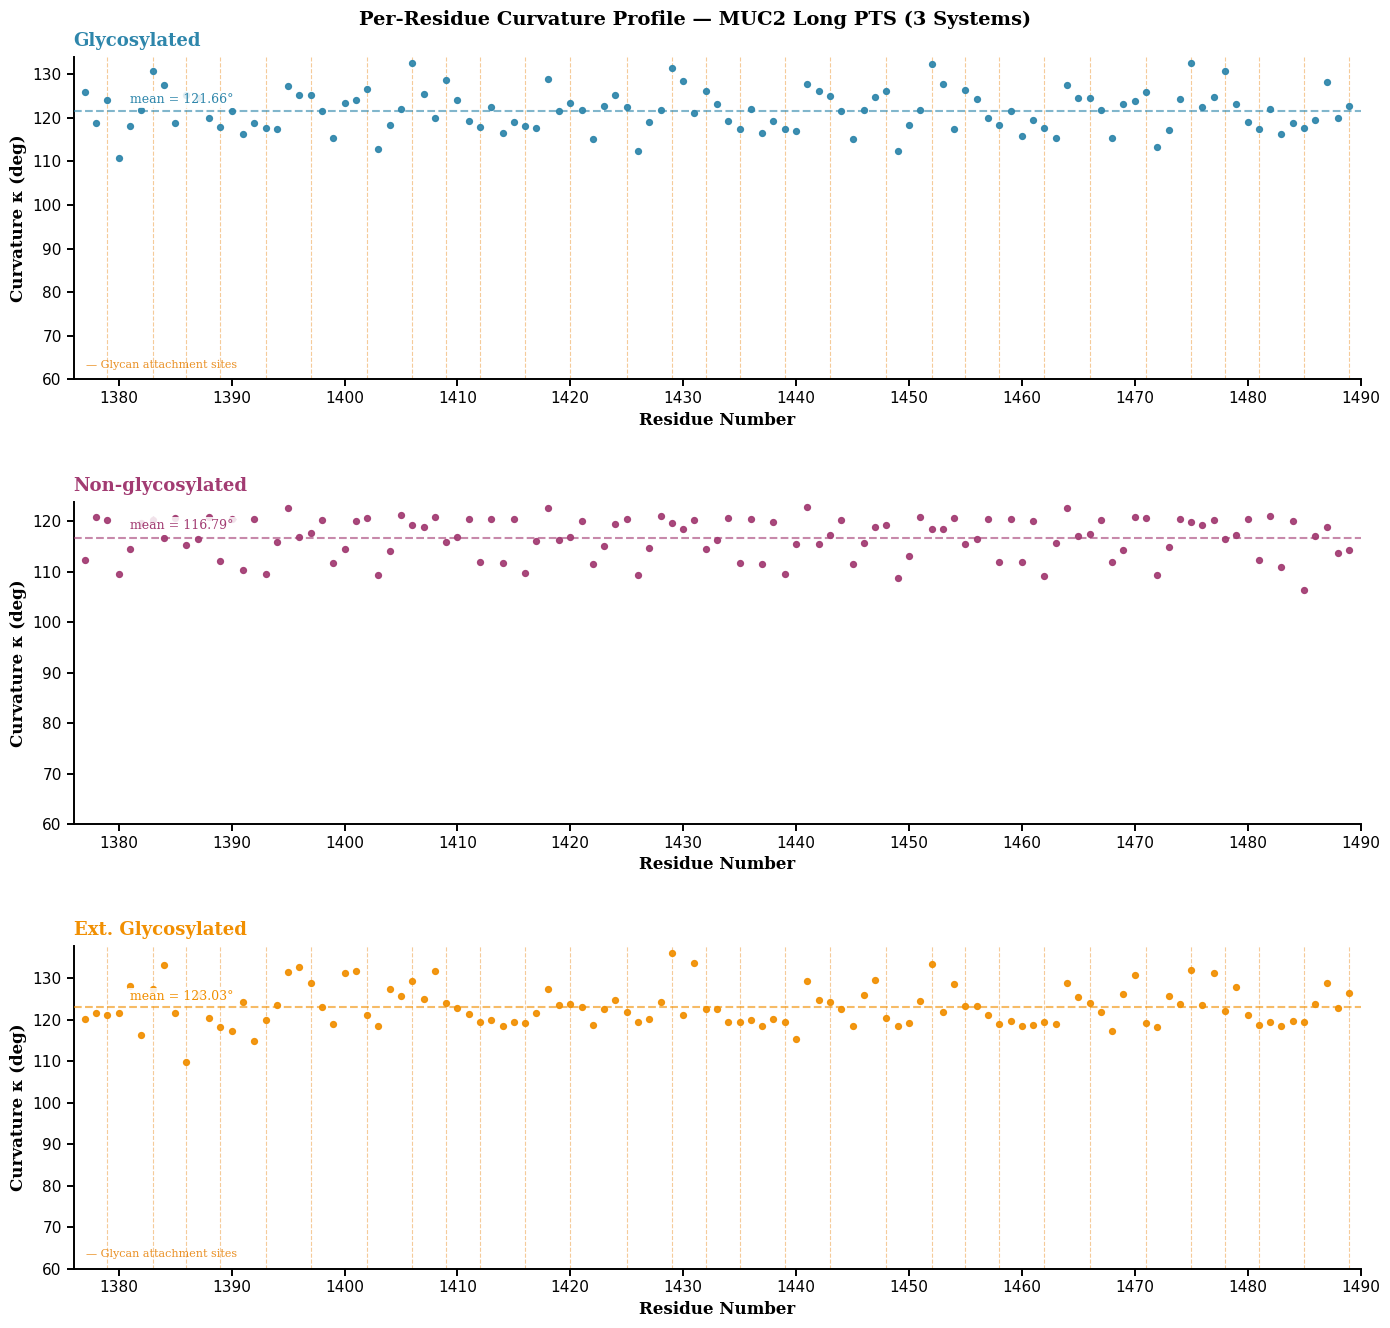

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_profile_3sys.png


In [180]:
# ── Figure: Per-Residue Curvature Profile — 3 panels stacked ─────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 13.5), dpi=100)
fig.set_facecolor("white")

prof_info = [
    (axes[0], gly_prof, "Glycosylated",      CLR_GLY, True),
    (axes[1], nog_prof, "Non-glycosylated",  CLR_NOG, False),
    (axes[2], ext_prof, "Ext. Glycosylated", CLR_EXT, True),
]

for ax, prof, sys_label, sys_color, show_glycans in prof_info:
    kappa_deg = prof[:, 3]
    se_deg    = prof[:, 4]
    n_res     = len(kappa_deg)
    r_idx     = np.arange(n_res) + RES_OFFSET

    if show_glycans:
        for r in GLYCAN_RES:
            ax.axvline(r, color="#E67E00", linewidth=0.8, linestyle="--", alpha=0.4, zorder=1)
        ax.text(0.01, 0.03, "— Glycan attachment sites",
                transform=ax.transAxes, fontsize=8, fontname="DejaVu Serif",
                color="#E67E00", alpha=0.85, va="bottom", ha="left")

    ax.vlines(r_idx, kappa_deg - se_deg, kappa_deg + se_deg,
              color=sys_color, linewidth=0.8, alpha=0.35, zorder=2)
    ax.scatter(r_idx, kappa_deg, color=sys_color, s=18, zorder=4, alpha=0.92)

    # Mean line with inline text annotation — white background, inside axes
    mean_val = kappa_deg.mean()
    ax.axhline(mean_val, color=sys_color, linewidth=1.5, linestyle="--", alpha=0.6, zorder=3)
    ax.text(r_idx[4], mean_val + 1.0, f"mean = {mean_val:.2f}°",
            fontsize=9, fontname="DejaVu Serif", color=sys_color,
            va="bottom", ha="left", zorder=5,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))

    ax.set_title(sys_label, fontsize=13, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=8, loc="left")
    ax.set_ylabel("Curvature κ (deg)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlabel("Residue Number", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlim(r_idx[0] - 1, r_idx[-1] + 1)
    ax.set_ylim(60, None)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4); ax.spines["bottom"].set_linewidth(1.4)
    ax.tick_params(labelsize=11, length=5, width=1.4, direction="out")

fig.suptitle("Per-Residue Curvature Profile — MUC2 Long PTS (3 Systems)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
plt.subplots_adjust(hspace=0.38)
out = os.path.join(output_dir, "curvature_profile_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

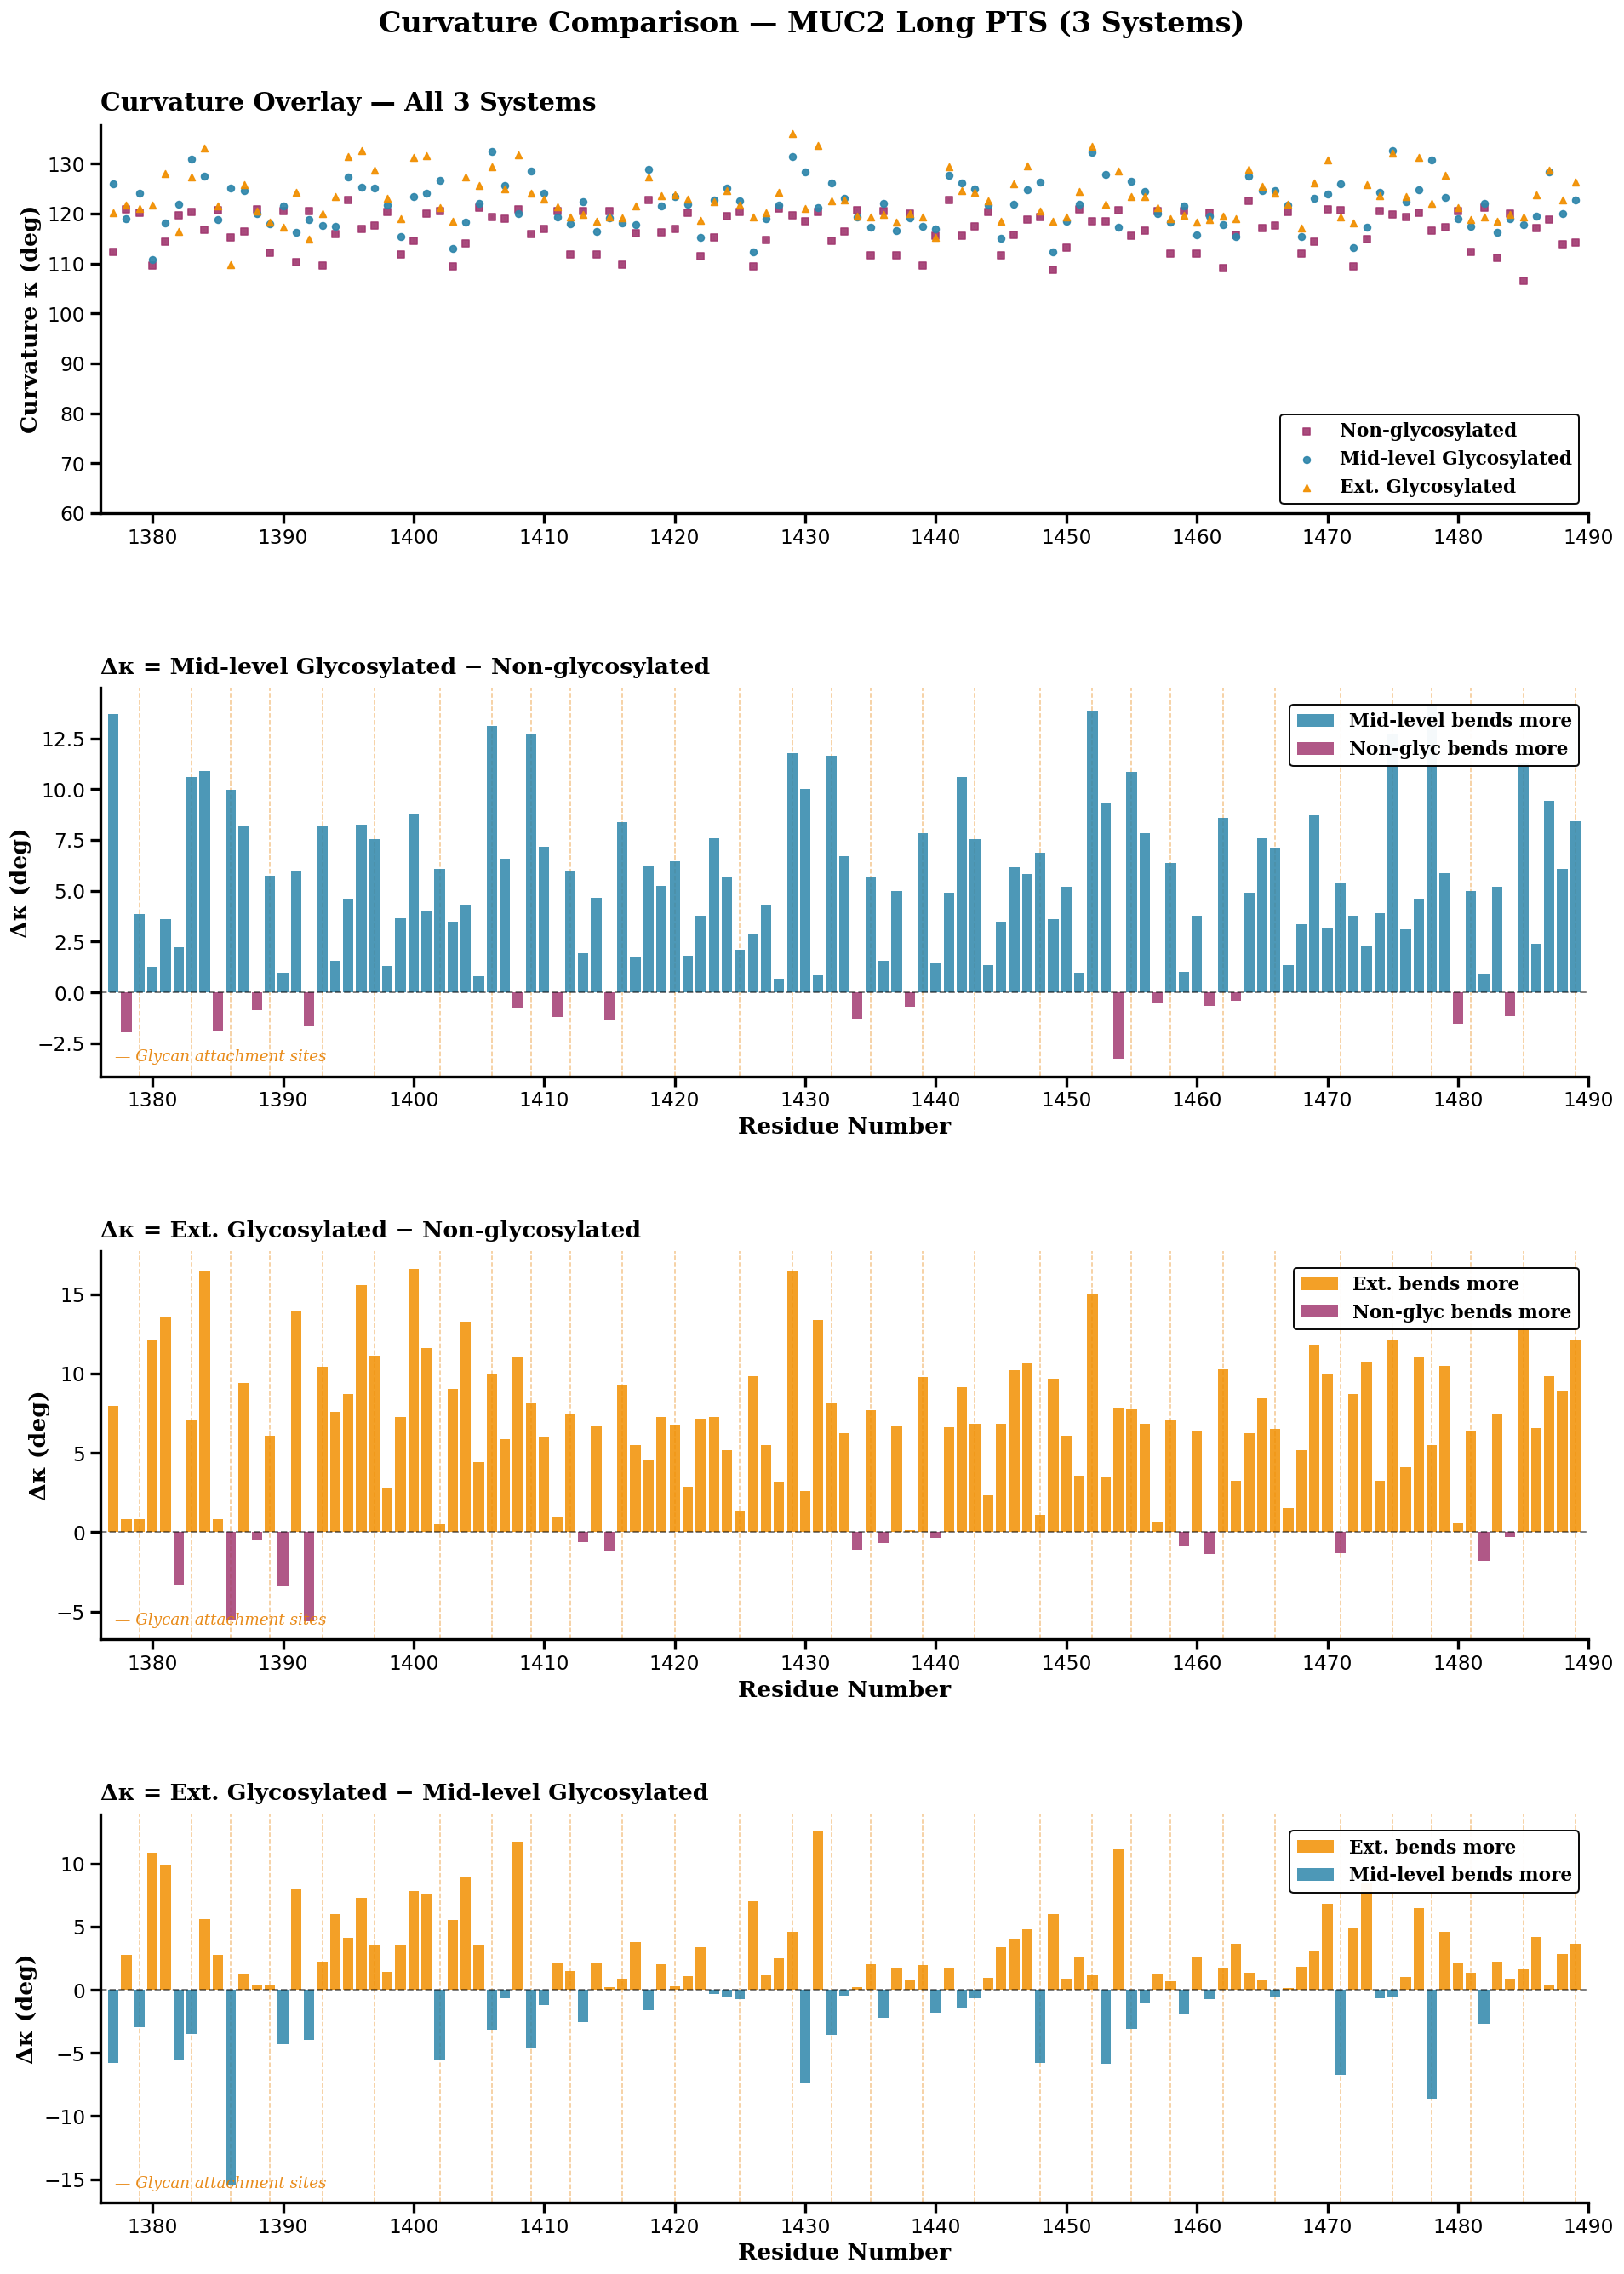

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_comparison_3sys.png


In [181]:
# ── Figure: 3-System Curvature Overlay + Delta panels ────────────────────────
kappa_gly_d = gly_prof[:, 3];  se_gly_d = gly_prof[:, 4]
kappa_nog_d = nog_prof[:, 3];  se_nog_d = nog_prof[:, 4]
kappa_ext_d = ext_prof[:, 3];  se_ext_d = ext_prof[:, 4]

n_common = min(len(kappa_gly_d), len(kappa_nog_d), len(kappa_ext_d))
r_common = np.arange(n_common) + RES_OFFSET
kappa_gly_d = kappa_gly_d[:n_common]; se_gly_d = se_gly_d[:n_common]
kappa_nog_d = kappa_nog_d[:n_common]; se_nog_d = se_nog_d[:n_common]
kappa_ext_d = kappa_ext_d[:n_common]; se_ext_d = se_ext_d[:n_common]

delta_gly_nog = kappa_gly_d - kappa_nog_d
delta_ext_nog = kappa_ext_d - kappa_nog_d
delta_ext_gly = kappa_ext_d - kappa_gly_d

fig, axes = plt.subplots(4, 1, figsize=(16, 22), dpi=120)
fig.set_facecolor("white")

# Panel 1: Overlay — canonical order Non-glycosylated -> Mid-level Glycosylated -> Ext. Glycosylated
ax = axes[0]
mkr_info = [
    (r_common, kappa_nog_d, se_nog_d, CLR_NOG, "s", "Non-glycosylated"),
    (r_common, kappa_gly_d, se_gly_d, CLR_GLY, "o", "Mid-level Glycosylated"),
    (r_common, kappa_ext_d, se_ext_d, CLR_EXT, "^", "Ext. Glycosylated"),
]
for ri, kd, se, clr, mkr, lbl in mkr_info:
    ax.vlines(ri, kd - se, kd + se, color=clr, linewidth=1.0, alpha=0.28, zorder=2)
    ax.scatter(ri, kd, color=clr, s=22, zorder=4, alpha=0.92, marker=mkr, label=lbl)
ax.set_ylabel("Curvature \u03ba (deg)", fontsize=16,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Curvature Overlay \u2014 All 3 Systems", fontsize=18,
             fontname="DejaVu Serif", fontweight="bold", pad=10, loc="left")
leg = ax.legend(fontsize=13, framealpha=0.95, edgecolor="black", loc="lower right",
                prop={"family": "DejaVu Serif", "size": 13, "weight": "bold"})
leg.get_frame().set_linewidth(1.2)
ax.set_xlim(r_common[0] - 1, r_common[-1] + 1)
ax.set_ylim(60, None)
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.set_facecolor("white")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")

# Panels 2-4: Delta kappa
delta_info = [
    (axes[1], delta_gly_nog, CLR_GLY, CLR_NOG,
     "\u0394\u03ba = Mid-level Glycosylated \u2212 Non-glycosylated",
     "Mid-level bends more", "Non-glyc bends more"),
    (axes[2], delta_ext_nog, CLR_EXT, CLR_NOG,
     "\u0394\u03ba = Ext. Glycosylated \u2212 Non-glycosylated",
     "Ext. bends more", "Non-glyc bends more"),
    (axes[3], delta_ext_gly, CLR_EXT, CLR_GLY,
     "\u0394\u03ba = Ext. Glycosylated \u2212 Mid-level Glycosylated",
     "Ext. bends more", "Mid-level bends more"),
]

for ax, delta, clr_pos, clr_neg, title, lbl_pos, lbl_neg in delta_info:
    for r in GLYCAN_RES:
        ax.axvline(r, color="#E67E00", linewidth=0.9, linestyle="--", alpha=0.45, zorder=1)
    ax.text(0.01, 0.03, "\u2014 Glycan attachment sites",
            transform=ax.transAxes, fontsize=11, fontname="DejaVu Serif",
            color="#E67E00", alpha=0.90, va="bottom", ha="left", fontstyle="italic")

    pos = delta >= 0; neg = delta < 0
    ax.bar(r_common[pos], delta[pos], color=clr_pos, alpha=0.85, width=0.8,
           label=lbl_pos, zorder=2)
    ax.bar(r_common[neg], delta[neg], color=clr_neg, alpha=0.85, width=0.8,
           label=lbl_neg, zorder=2)
    ax.axhline(0, color="black", linewidth=1.2, linestyle="--", alpha=0.5)
    ax.set_ylabel("\u0394\u03ba (deg)", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlabel("Residue Number", fontsize=16,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=16, fontname="DejaVu Serif", fontweight="bold",
                 pad=10, loc="left")
    leg = ax.legend(fontsize=13, framealpha=0.95, edgecolor="black",
                    loc="upper right", bbox_to_anchor=(1.0, 0.98),
                    prop={"family": "DejaVu Serif", "size": 13, "weight": "bold"})
    leg.get_frame().set_linewidth(1.2)
    ax.set_xlim(r_common[0] - 1, r_common[-1] + 1)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(2.0); ax.spines["bottom"].set_linewidth(2.0)
    ax.tick_params(labelsize=14, length=7, width=2.0, direction="out")

fig.suptitle("Curvature Comparison \u2014 MUC2 Long PTS (3 Systems)",
             fontsize=20, fontname="DejaVu Serif", fontweight="bold", y=1.01)
plt.tight_layout()
plt.subplots_adjust(hspace=0.45)
out = os.path.join(output_dir, "curvature_comparison_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


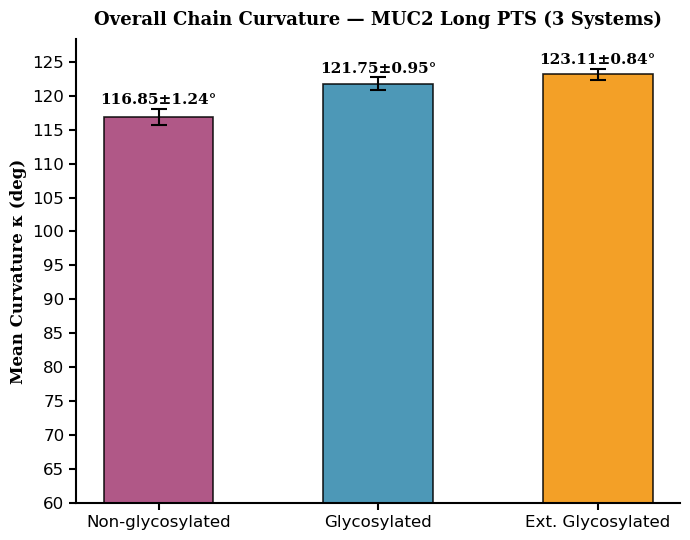

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_summary_3sys.png


In [182]:
# ── Figure: Overall Curvature Summary — 3 Systems ────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=100)
fig.set_facecolor("white")

systems = ["Non-glycosylated", "Glycosylated", "Ext. Glycosylated"]
means   = [nog_frame[:, 2].mean(), gly_frame[:, 2].mean(), ext_frame[:, 2].mean()]
stds    = [nog_frame[:, 2].std(),  gly_frame[:, 2].std(),  ext_frame[:, 2].std()]
colors  = [CLR_NOG, CLR_GLY, CLR_EXT]

bars = ax.bar(systems, means, yerr=stds, color=colors, alpha=0.85,
              edgecolor="black", linewidth=1.2, width=0.5,
              error_kw=dict(elinewidth=1.5, capsize=6, capthick=1.5, ecolor="black"))

for bar, mean, std in zip(bars, means, stds):
    ax.text(bar.get_x() + bar.get_width() / 2, mean + std + 0.2,
            f"{mean:.2f}±{std:.2f}°",
            ha="center", va="bottom", fontsize=11,
            fontname="DejaVu Serif", fontweight="bold")

ax.set_ylabel("Mean Curvature κ (deg)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Overall Chain Curvature — MUC2 Long PTS (3 Systems)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=12, length=5, width=1.5, direction="out")
ax.set_ylim(60, max(means) + max(stds) + 4)
ax.yaxis.set_major_locator(ticker.MultipleLocator(5))

plt.tight_layout()
out = os.path.join(output_dir, "curvature_summary_3sys.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

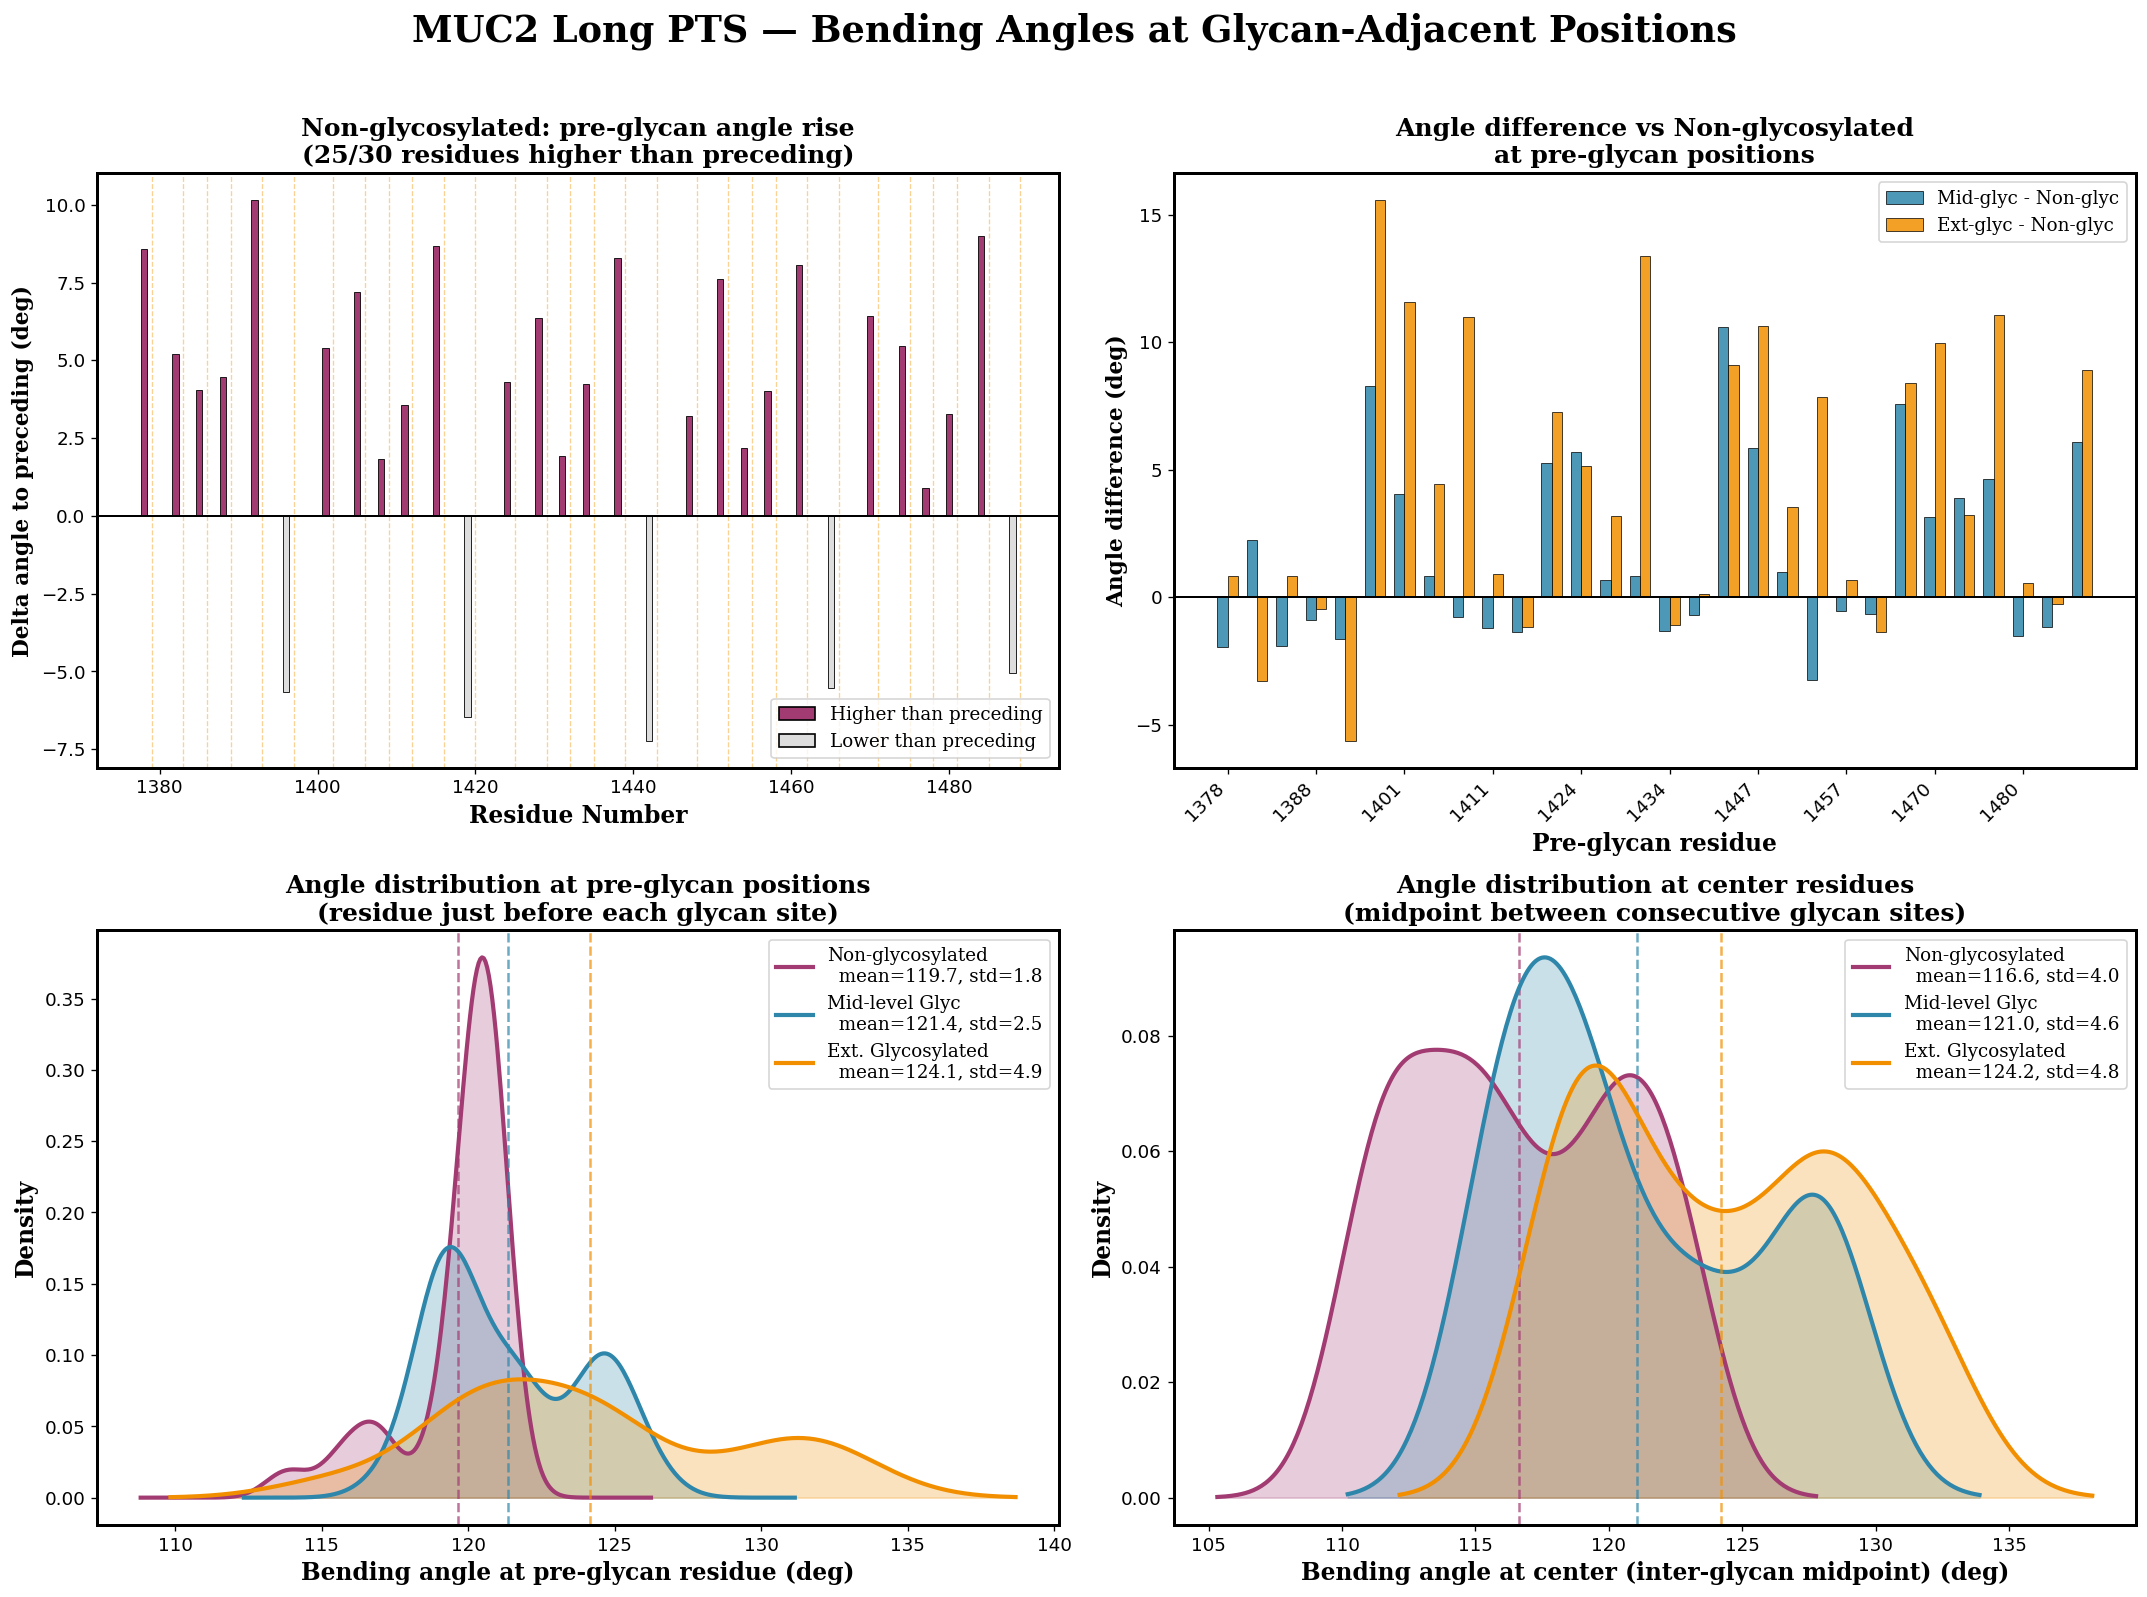

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_preglycan_analysis.png

No-glyc: pre-glycan residues with angle HIGHER than preceding:
  Res 1378: 120.86 deg  (prev 1377: 112.28 deg,  +8.57 deg)
  Res 1382: 119.64 deg  (prev 1381: 114.45 deg,  +5.19 deg)
  Res 1385: 120.73 deg  (prev 1384: 116.67 deg,  +4.06 deg)
  Res 1388: 120.89 deg  (prev 1387: 116.42 deg,  +4.47 deg)
  Res 1392: 120.47 deg  (prev 1391: 110.32 deg,  +10.14 deg)
  Res 1401: 120.00 deg  (prev 1400: 114.61 deg,  +5.40 deg)
  Res 1405: 121.24 deg  (prev 1404: 114.03 deg,  +7.21 deg)
  Res 1408: 120.79 deg  (prev 1407: 118.97 deg,  +1.83 deg)
  Res 1411: 120.51 deg  (prev 1410: 116.94 deg,  +3.56 deg)
  Res 1415: 120.46 deg  (prev 1414: 111.78 deg,  +8.68 deg)
  Res 1424: 119.47 deg  (prev 1423: 115.16 deg,  +4.31 deg)
  Res 1428: 121.04 deg  (prev 1427: 114.67 deg,  +6.36 deg)
  Res 1431: 120.32 deg  (prev 1430: 118.40 deg,  +1.92 deg)
  Res 1434: 120.62 deg  (prev 1433: 116.38 

In [183]:
from scipy.stats import gaussian_kde

# ----------------------------------------------------------------
# Pre-glycan and center-residue angle analysis
# ----------------------------------------------------------------
n_common  = min(len(nog_prof), len(gly_prof), len(ext_prof))
res_nums  = np.arange(n_common) + RES_OFFSET

kap_nog = nog_prof[:n_common, 3]   # degrees
kap_gly = gly_prof[:n_common, 3]
kap_ext = ext_prof[:n_common, 3]
se_nog  = nog_prof[:n_common, 4]
se_gly  = gly_prof[:n_common, 4]
se_ext  = ext_prof[:n_common, 4]

# Pre-glycan residues (one before each glycan site)
pre_res = GLYCAN_RES - 1
pre_res = pre_res[(pre_res >= res_nums[0]) & (pre_res <= res_nums[-1])]
pre_idx = pre_res - RES_OFFSET

# Which no-glyc pre-glycan residues are higher than their preceding residue
is_higher = np.array([kap_nog[i] > kap_nog[i-1] if i > 0 else False for i in pre_idx])
diff_to_prev = np.array([kap_nog[i] - kap_nog[i-1] if i > 0 else 0.0 for i in pre_idx])

# Center residues: midpoint between consecutive glycan sites
ctr_res = np.array([
    int(round((GLYCAN_RES[j] + GLYCAN_RES[j+1]) / 2))
    for j in range(len(GLYCAN_RES)-1)
])
ctr_res = ctr_res[(ctr_res >= res_nums[0]) & (ctr_res <= res_nums[-1])]
ctr_idx = ctr_res - RES_OFFSET

fig, axes = plt.subplots(2, 2, figsize=(18, 13), dpi=120)
fig.set_facecolor("white")

# ---- Panel A: No-glyc pre-glycan residues, color-coded by direction ----
ax = axes[0, 0]
colors_bar = [CLR_NOG if h else "#DDDDDD" for h in is_higher]
ax.bar(pre_res, diff_to_prev, color=colors_bar, edgecolor="black",
       linewidth=0.5, width=0.8)
ax.axhline(0, color="black", linewidth=1.2, linestyle="-")
for g in GLYCAN_RES:
    ax.axvline(g, color="#F39C12", linewidth=0.8, linestyle="--", alpha=0.45, zorder=0)
ax.set_xlabel("Residue Number", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Delta angle to preceding (deg)", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_title(
    f"Non-glycosylated: pre-glycan angle rise\n"
    f"({is_higher.sum()}/{len(is_higher)} residues higher than preceding)",
    fontsize=15, fontname="DejaVu Serif", fontweight="bold")
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor=CLR_NOG, edgecolor="black", label="Higher than preceding"),
    Patch(facecolor="#DDDDDD", edgecolor="black", label="Lower than preceding"),
], fontsize=11, loc="lower right", prop={"family":"DejaVu Serif","size":11})
ax.tick_params(labelsize=11)
for sp in ax.spines.values(): sp.set_linewidth(1.8)

# ---- Panel B: System differences (gly-nog, ext-nog) at pre-glycan positions ----
ax = axes[0, 1]
diff_gly_nog = kap_gly[pre_idx] - kap_nog[pre_idx]
diff_ext_nog = kap_ext[pre_idx] - kap_nog[pre_idx]
x_tick = np.arange(len(pre_res))
w = 0.35
ax.bar(x_tick - w/2, diff_gly_nog, width=w, color=CLR_GLY,
       alpha=0.85, edgecolor="black", linewidth=0.5, label="Mid-glyc - Non-glyc")
ax.bar(x_tick + w/2, diff_ext_nog, width=w, color=CLR_EXT,
       alpha=0.85, edgecolor="black", linewidth=0.5, label="Ext-glyc - Non-glyc")
ax.axhline(0, color="black", linewidth=1.2)
ax.set_xticks(x_tick[::3])
ax.set_xticklabels(pre_res[::3], rotation=45, ha="right", fontsize=10)
ax.set_xlabel("Pre-glycan residue", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Angle difference (deg)", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Angle difference vs Non-glycosylated\nat pre-glycan positions",
             fontsize=15, fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=11, prop={"family":"DejaVu Serif","size":11})
ax.tick_params(labelsize=11)
for sp in ax.spines.values(): sp.set_linewidth(1.8)

# ---- Panel C: KDE distribution of angles at pre-glycan positions ----
ax = axes[1, 0]
for kap, clr, lbl in [
    (kap_nog[pre_idx], CLR_NOG, "Non-glycosylated"),
    (kap_gly[pre_idx], CLR_GLY, "Mid-level Glyc"),
    (kap_ext[pre_idx], CLR_EXT, "Ext. Glycosylated"),
]:
    kde = gaussian_kde(kap, bw_method=0.4)
    xs  = np.linspace(kap.min()-5, kap.max()+5, 300)
    ax.fill_between(xs, kde(xs), alpha=0.25, color=clr)
    ax.plot(xs, kde(xs), color=clr, linewidth=2.5, label=f"{lbl}\n  mean={kap.mean():.1f}, std={kap.std():.1f}")
    ax.axvline(kap.mean(), color=clr, linewidth=1.5, linestyle="--", alpha=0.7)
ax.set_xlabel("Bending angle at pre-glycan residue (deg)", fontsize=14,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Density", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Angle distribution at pre-glycan positions\n(residue just before each glycan site)",
             fontsize=15, fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=11, prop={"family":"DejaVu Serif","size":11})
ax.tick_params(labelsize=11)
for sp in ax.spines.values(): sp.set_linewidth(1.8)

# ---- Panel D: KDE distribution at center-between-glycan positions ----
ax = axes[1, 1]
for kap, clr, lbl in [
    (kap_nog[ctr_idx], CLR_NOG, "Non-glycosylated"),
    (kap_gly[ctr_idx], CLR_GLY, "Mid-level Glyc"),
    (kap_ext[ctr_idx], CLR_EXT, "Ext. Glycosylated"),
]:
    kde = gaussian_kde(kap, bw_method=0.4)
    xs  = np.linspace(kap.min()-5, kap.max()+5, 300)
    ax.fill_between(xs, kde(xs), alpha=0.25, color=clr)
    ax.plot(xs, kde(xs), color=clr, linewidth=2.5, label=f"{lbl}\n  mean={kap.mean():.1f}, std={kap.std():.1f}")
    ax.axvline(kap.mean(), color=clr, linewidth=1.5, linestyle="--", alpha=0.7)
ax.set_xlabel("Bending angle at center (inter-glycan midpoint) (deg)", fontsize=14,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Density", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Angle distribution at center residues\n(midpoint between consecutive glycan sites)",
             fontsize=15, fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=11, prop={"family":"DejaVu Serif","size":11})
ax.tick_params(labelsize=11)
for sp in ax.spines.values(): sp.set_linewidth(1.8)

fig.suptitle(
    "MUC2 Long PTS — Bending Angles at Glycan-Adjacent Positions",
    fontsize=22, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(output_dir, "curvature_preglycan_analysis.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

# Summary printout
print("\nNo-glyc: pre-glycan residues with angle HIGHER than preceding:")
for pg_res, pg_idx_v, h, d in zip(pre_res, pre_idx, is_higher, diff_to_prev):
    if h:
        print(f"  Res {pg_res}: {kap_nog[pg_idx_v]:.2f} deg  (prev {pg_res-1}: {kap_nog[pg_idx_v-1]:.2f} deg,  +{d:.2f} deg)")

print("\nSystem-mean differences at pre-glycan positions:")
print(f"  Mid-glyc - Non-glyc: {diff_gly_nog.mean():+.2f} +/- {diff_gly_nog.std():.2f} deg")
print(f"  Ext-glyc - Non-glyc: {diff_ext_nog.mean():+.2f} +/- {diff_ext_nog.std():.2f} deg")


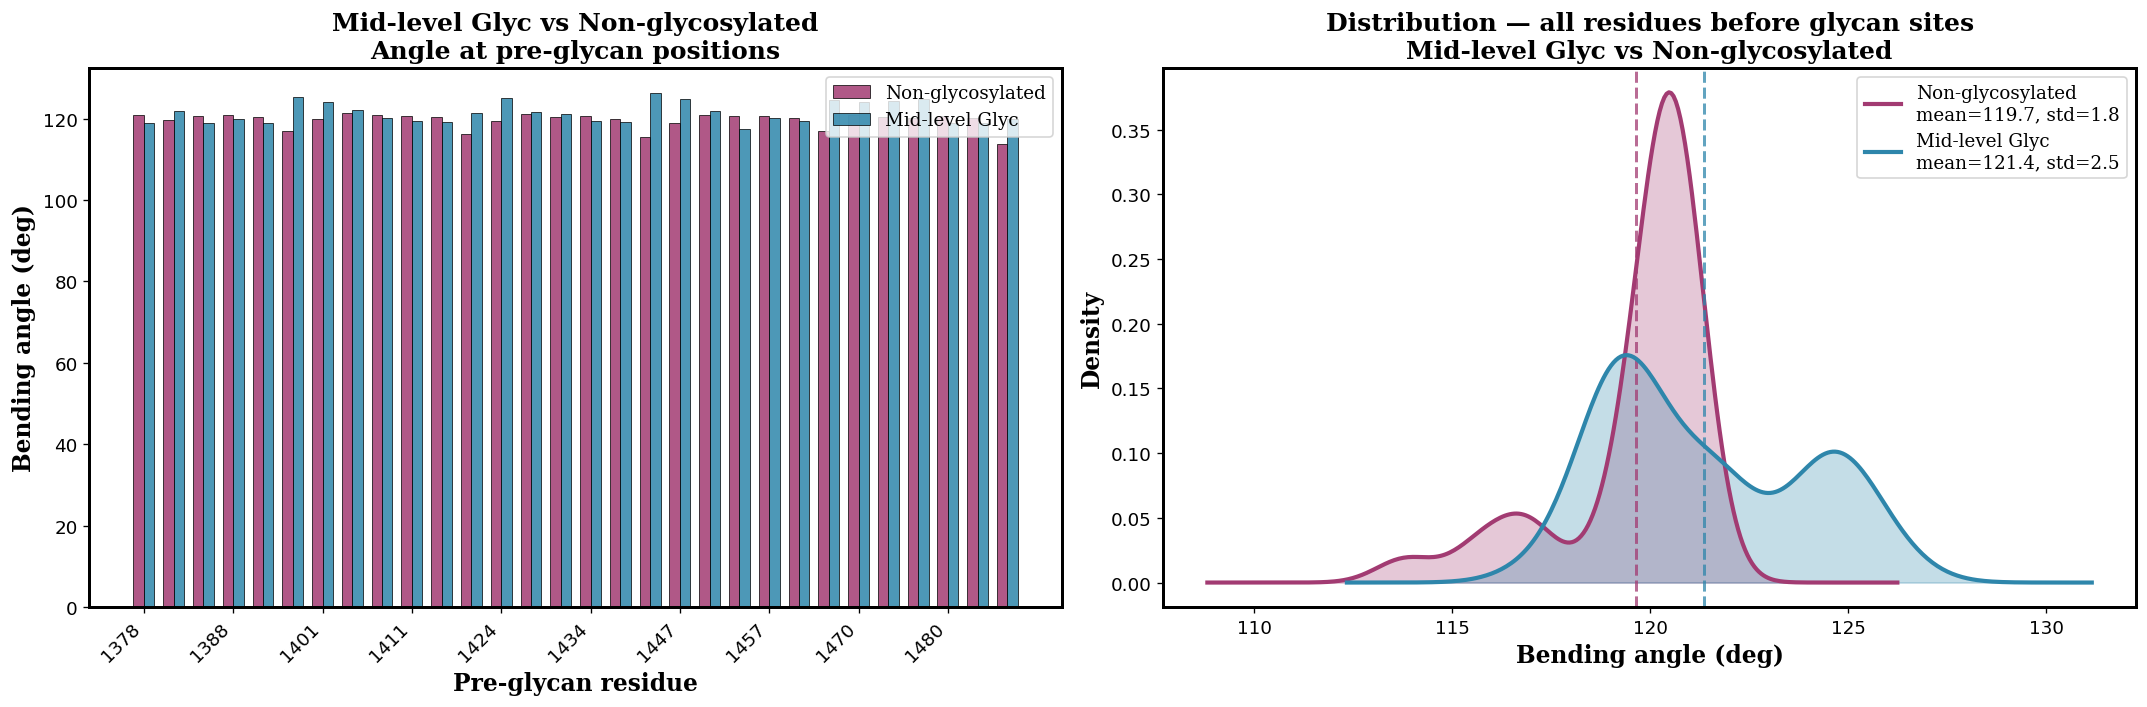

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_preglycan_midglyc_vs_nog.png


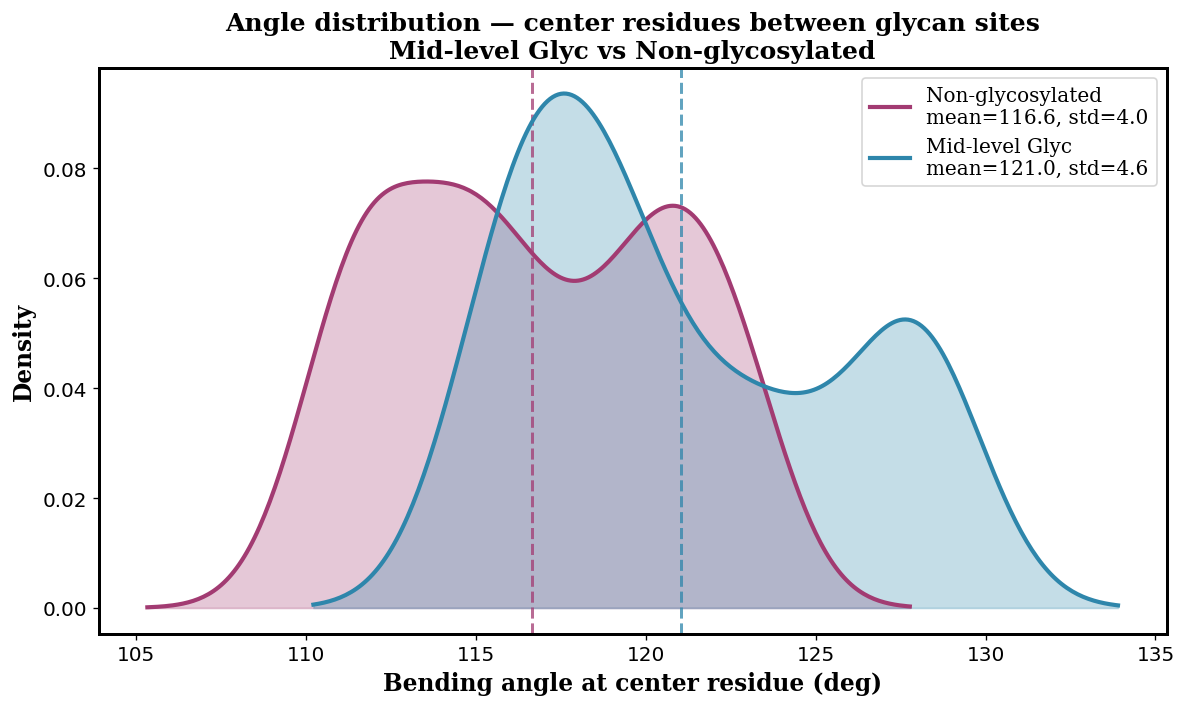

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_center_midglyc_vs_nog.png

Mid-level Glyc vs Non-glyc at pre-glycan: mean diff = +1.72 deg
Mid-level Glyc vs Non-glyc at center:     mean diff = +4.40 deg


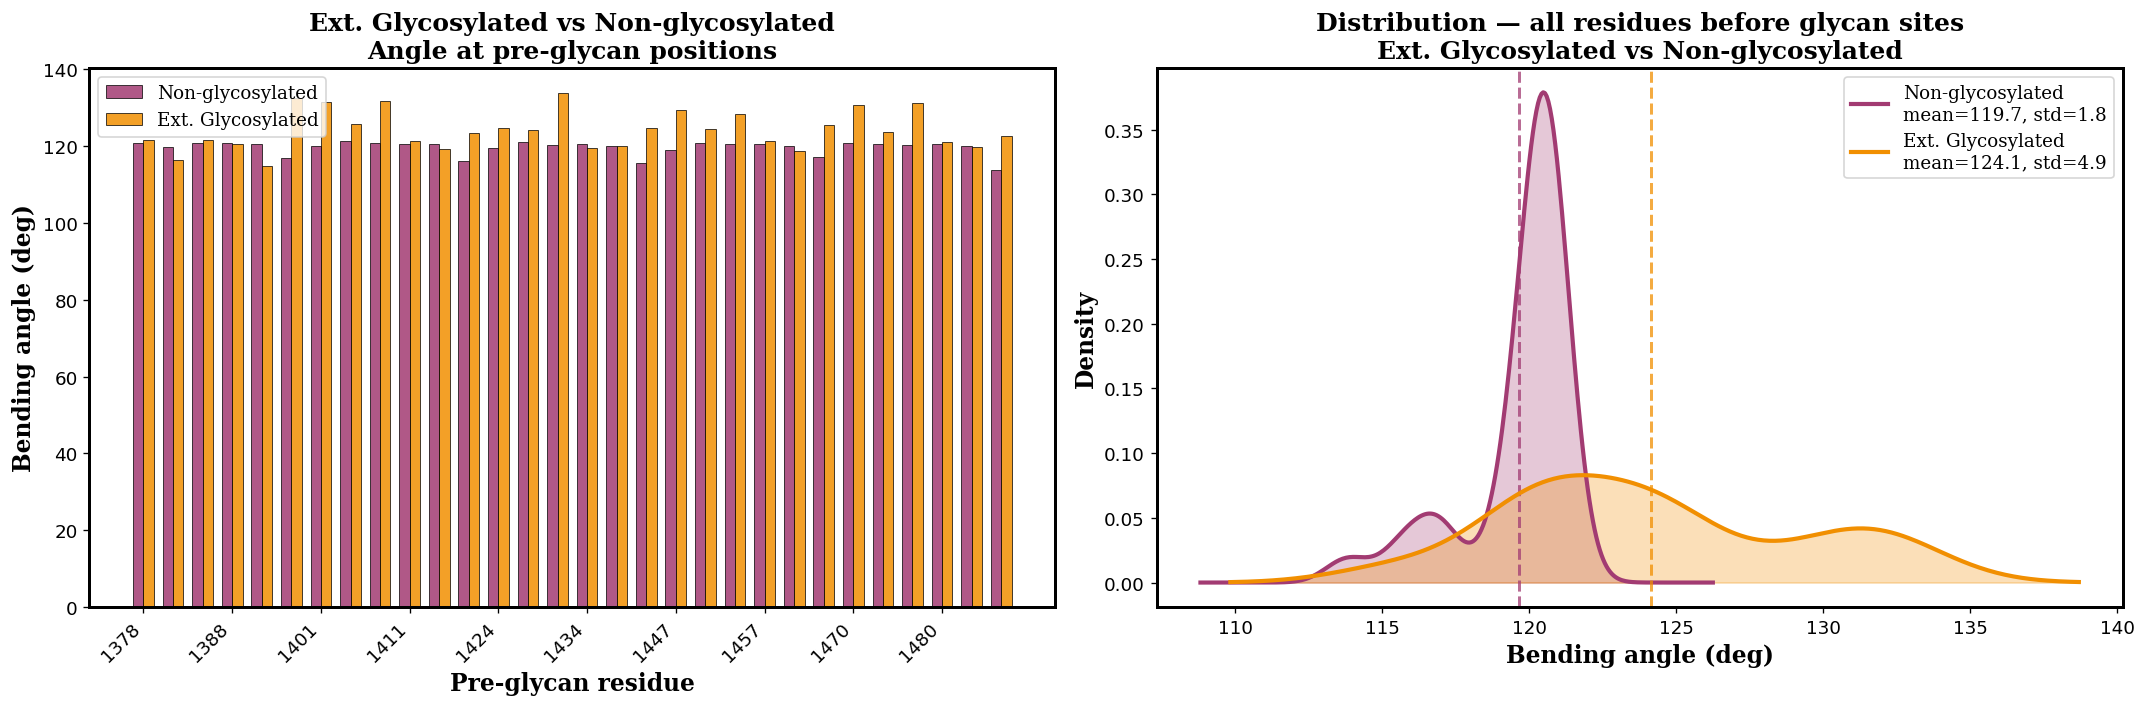

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_preglycan_extglyc_vs_nog.png


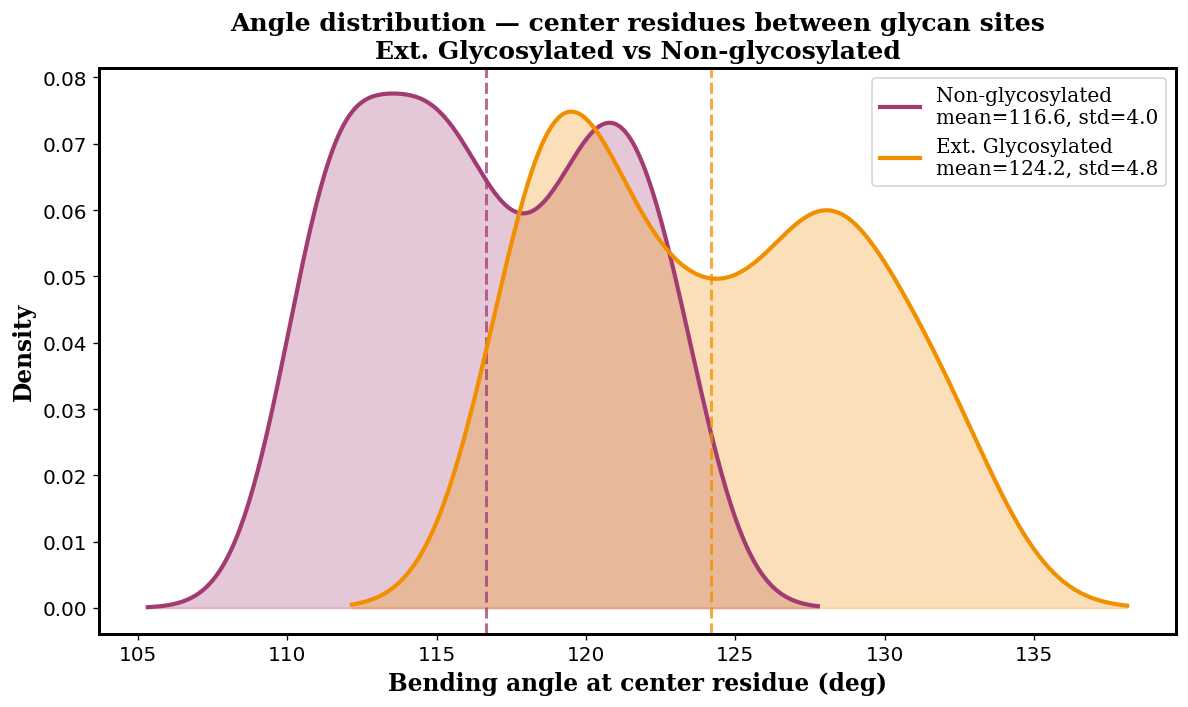

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/curvature_center_extglyc_vs_nog.png

Ext. Glycosylated vs Non-glyc at pre-glycan: mean diff = +4.50 deg
Ext. Glycosylated vs Non-glyc at center:     mean diff = +7.56 deg


In [184]:
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch

# ----------------------------------------------------------------
# Pairwise pre-glycan and center-residue comparisons
# ----------------------------------------------------------------
n_common = min(len(nog_prof), len(gly_prof), len(ext_prof))
res_nums = np.arange(n_common) + RES_OFFSET

kap_nog = nog_prof[:n_common, 3]
kap_gly = gly_prof[:n_common, 3]
kap_ext = ext_prof[:n_common, 3]
se_nog  = nog_prof[:n_common, 4]
se_gly  = gly_prof[:n_common, 4]
se_ext  = ext_prof[:n_common, 4]

pre_res = GLYCAN_RES - 1
pre_res = pre_res[(pre_res >= res_nums[0]) & (pre_res <= res_nums[-1])]
pre_idx = pre_res - RES_OFFSET

ctr_res = np.array([
    int(round((GLYCAN_RES[j] + GLYCAN_RES[j+1]) / 2))
    for j in range(len(GLYCAN_RES)-1)
])
ctr_res = ctr_res[(ctr_res >= res_nums[0]) & (ctr_res <= res_nums[-1])]
ctr_idx = ctr_res - RES_OFFSET

comparisons = [
    ("Mid-level Glyc", CLR_GLY, kap_gly, se_gly, "midglyc"),
    ("Ext. Glycosylated", CLR_EXT, kap_ext, se_ext, "extglyc"),
]

for sys_label, sys_clr, kap_sys, se_sys, tag in comparisons:
    diff_pre = kap_sys[pre_idx] - kap_nog[pre_idx]
    diff_ctr = kap_sys[ctr_idx] - kap_nog[ctr_idx]

    # ---- Figure 1: Pre-glycan bar comparison + KDE ----
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), dpi=120)
    fig.set_facecolor("white")

    ax = axes[0]
    x = np.arange(len(pre_res))
    w = 0.35
    ax.bar(x - w/2, kap_nog[pre_idx], width=w, color=CLR_NOG, alpha=0.85,
           edgecolor="black", linewidth=0.5, label="Non-glycosylated")
    ax.bar(x + w/2, kap_sys[pre_idx], width=w, color=sys_clr, alpha=0.85,
           edgecolor="black", linewidth=0.5, label=sys_label)
    ax.set_xticks(x[::3])
    ax.set_xticklabels(pre_res[::3], rotation=45, ha="right", fontsize=10)
    ax.set_xlabel("Pre-glycan residue", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Bending angle (deg)", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(f"{sys_label} vs Non-glycosylated\nAngle at pre-glycan positions",
                 fontsize=15, fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=11, prop={"family":"DejaVu Serif","size":11})
    ax.tick_params(labelsize=11)
    for sp in ax.spines.values(): sp.set_linewidth(1.8)

    ax = axes[1]
    for kap, clr, lbl in [
        (kap_nog[pre_idx], CLR_NOG, f"Non-glycosylated\nmean={kap_nog[pre_idx].mean():.1f}, std={kap_nog[pre_idx].std():.1f}"),
        (kap_sys[pre_idx], sys_clr, f"{sys_label}\nmean={kap_sys[pre_idx].mean():.1f}, std={kap_sys[pre_idx].std():.1f}"),
    ]:
        kde = gaussian_kde(kap, bw_method=0.4)
        xs  = np.linspace(min(kap)-5, max(kap)+5, 300)
        ax.fill_between(xs, kde(xs), alpha=0.28, color=clr)
        ax.plot(xs, kde(xs), color=clr, linewidth=2.5, label=lbl)
        ax.axvline(kap.mean(), color=clr, linewidth=1.8, linestyle="--", alpha=0.75)
    ax.set_xlabel("Bending angle (deg)", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Density", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(f"Distribution — all residues before glycan sites\n{sys_label} vs Non-glycosylated",
                 fontsize=15, fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=11, prop={"family":"DejaVu Serif","size":11})
    ax.tick_params(labelsize=11)
    for sp in ax.spines.values(): sp.set_linewidth(1.8)

    plt.tight_layout()
    out1 = os.path.join(output_dir, f"curvature_preglycan_{tag}_vs_nog.png")
    plt.savefig(out1, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {out1}")

    # ---- Figure 2: Center residue KDE comparison ----
    fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
    fig.set_facecolor("white")
    for kap, clr, lbl in [
        (kap_nog[ctr_idx], CLR_NOG, f"Non-glycosylated\nmean={kap_nog[ctr_idx].mean():.1f}, std={kap_nog[ctr_idx].std():.1f}"),
        (kap_sys[ctr_idx], sys_clr, f"{sys_label}\nmean={kap_sys[ctr_idx].mean():.1f}, std={kap_sys[ctr_idx].std():.1f}"),
    ]:
        kde = gaussian_kde(kap, bw_method=0.4)
        xs  = np.linspace(min(kap)-5, max(kap)+5, 300)
        ax.fill_between(xs, kde(xs), alpha=0.28, color=clr)
        ax.plot(xs, kde(xs), color=clr, linewidth=2.5, label=lbl)
        ax.axvline(kap.mean(), color=clr, linewidth=1.8, linestyle="--", alpha=0.75)
    ax.set_xlabel("Bending angle at center residue (deg)", fontsize=14,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Density", fontsize=14, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(
        f"Angle distribution — center residues between glycan sites\n{sys_label} vs Non-glycosylated",
        fontsize=15, fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=12, prop={"family":"DejaVu Serif","size":12})
    ax.tick_params(labelsize=12)
    for sp in ax.spines.values(): sp.set_linewidth(1.8)
    plt.tight_layout()
    out2 = os.path.join(output_dir, f"curvature_center_{tag}_vs_nog.png")
    plt.savefig(out2, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {out2}")

    print(f"\n{sys_label} vs Non-glyc at pre-glycan: mean diff = {diff_pre.mean():+.2f} deg")
    print(f"{sys_label} vs Non-glyc at center:     mean diff = {diff_ctr.mean():+.2f} deg")


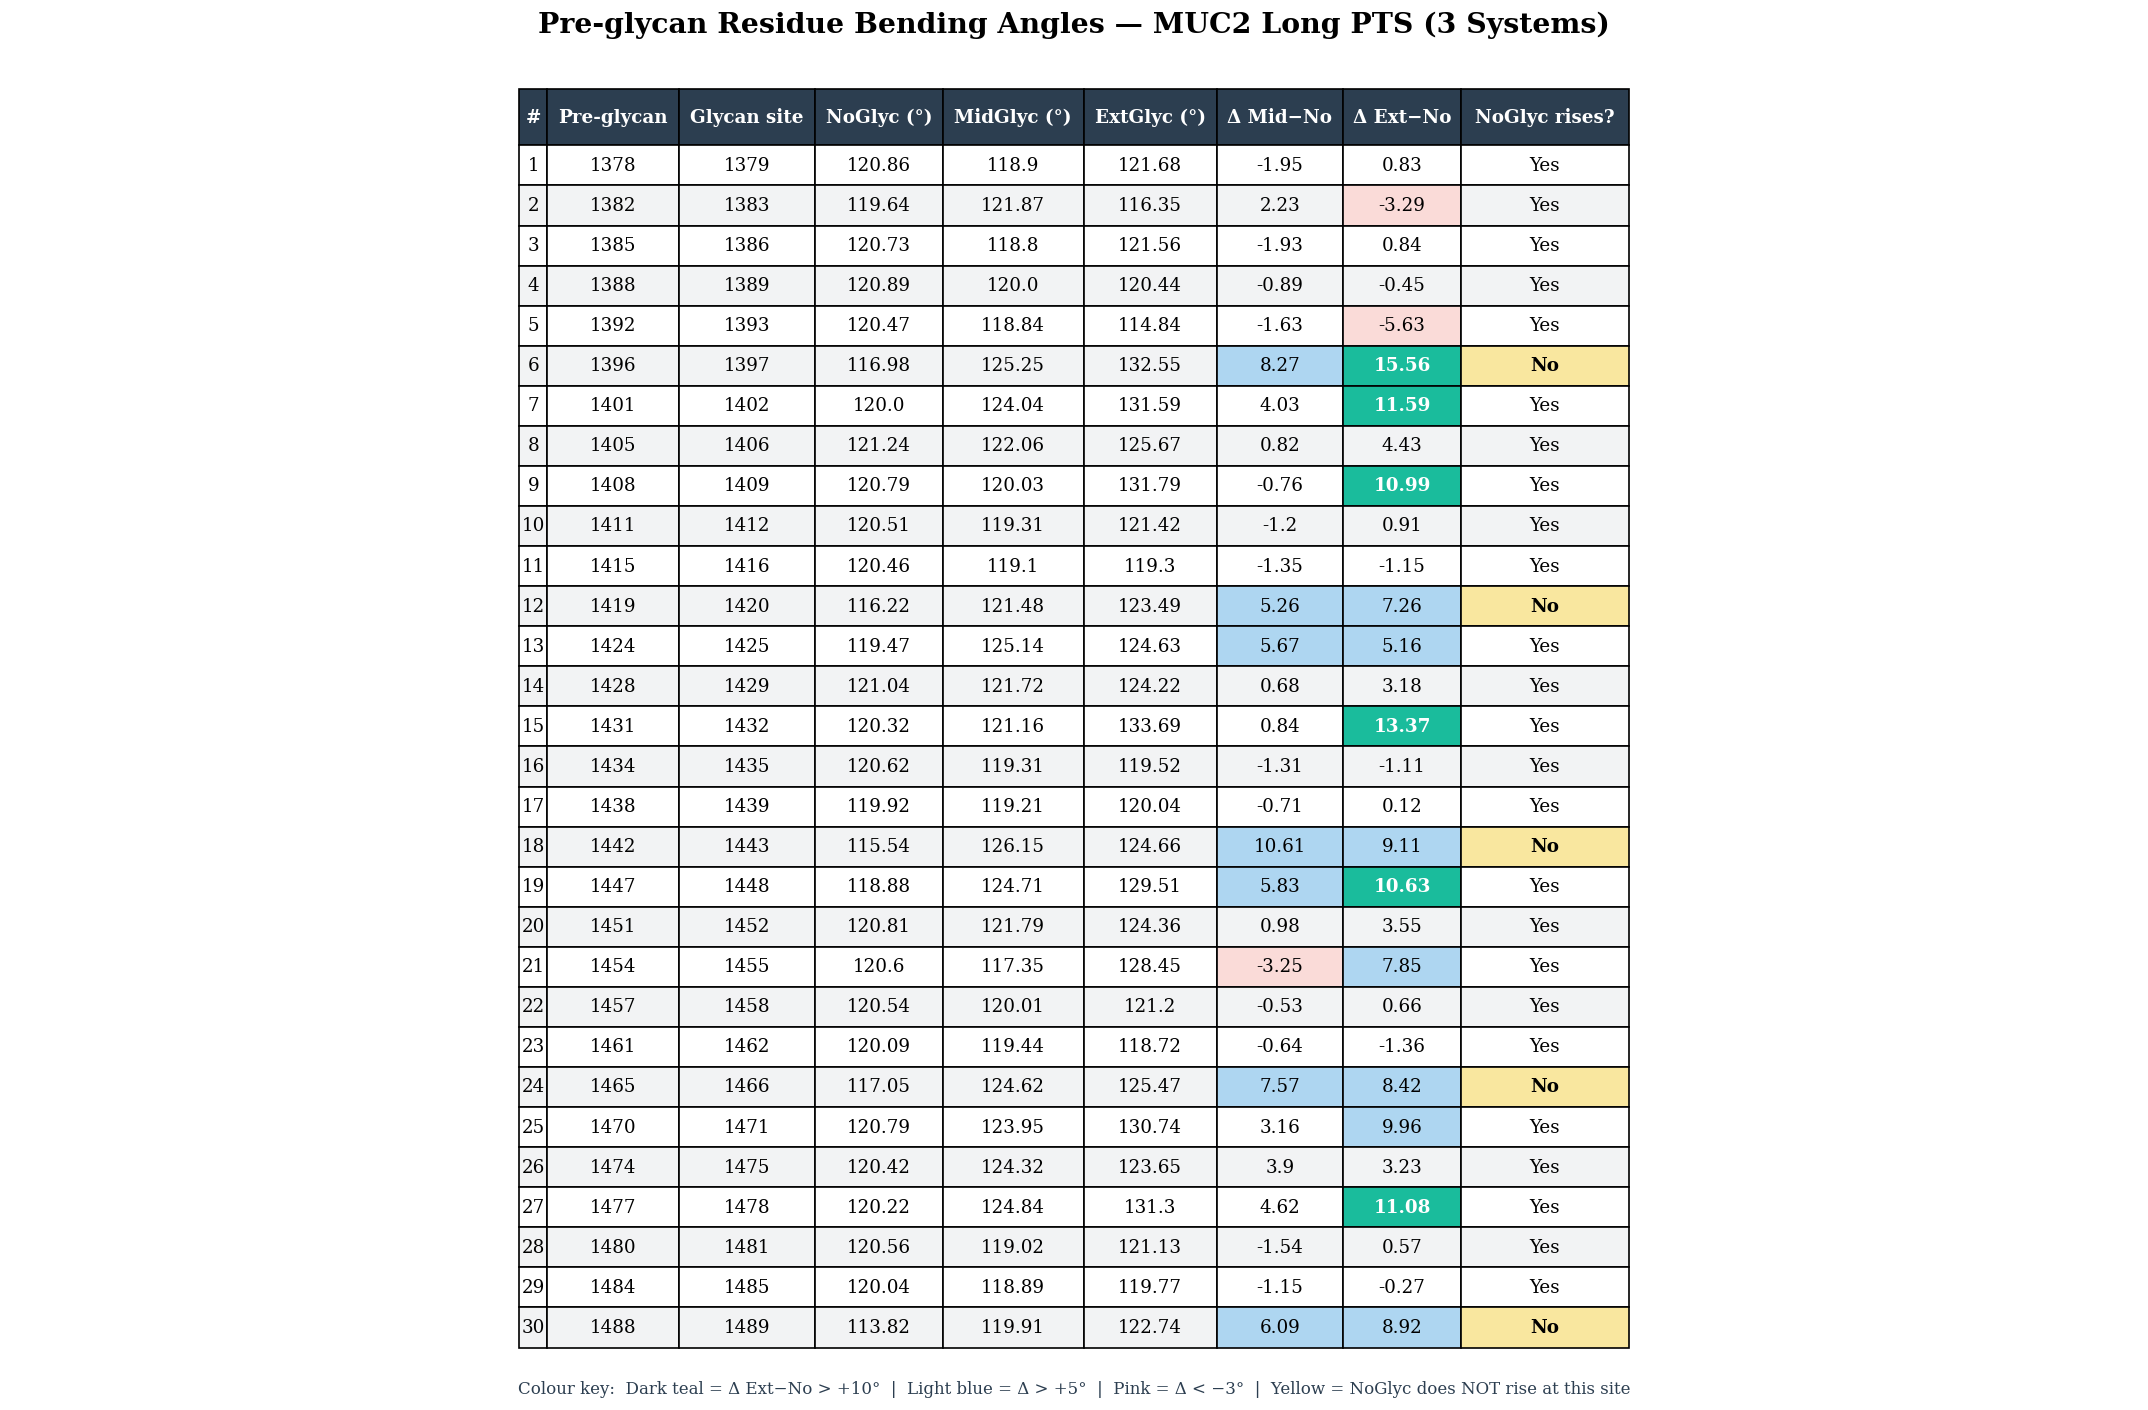

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/preglycan_angle_table.png


In [185]:
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

n_common = min(len(nog_prof), len(gly_prof), len(ext_prof))
res_nums = np.arange(n_common) + RES_OFFSET
kap_nog  = nog_prof[:n_common, 3]
kap_gly  = gly_prof[:n_common, 3]
kap_ext  = ext_prof[:n_common, 3]

pre_res = GLYCAN_RES - 1
pre_res = pre_res[(pre_res >= res_nums[0]) & (pre_res <= res_nums[-1])]
pre_idx = pre_res - RES_OFFSET

rows = []
for i, (pr, pg) in enumerate(zip(pre_res, GLYCAN_RES), 1):
    idx = pr - RES_OFFSET
    nog = kap_nog[idx]
    gly = kap_gly[idx]
    ext = kap_ext[idx]
    higher = "Yes" if (idx > 0 and nog > kap_nog[idx-1]) else "No"
    rows.append({
        "#":           i,
        "Pre-glycan":  pr,
        "Glycan site": pg,
        "NoGlyc (°)":  round(nog, 2),
        "MidGlyc (°)": round(gly, 2),
        "ExtGlyc (°)": round(ext, 2),
        "Δ Mid−No":    round(gly - nog, 2),
        "Δ Ext−No":    round(ext - nog, 2),
        "NoGlyc rises?": higher,
    })

df = pd.DataFrame(rows)

# ---- figure ----
fig, ax = plt.subplots(figsize=(18, 12), dpi=120)
fig.set_facecolor("white")
ax.axis("off")

col_labels = list(df.columns)
table_data = df.values.tolist()

tbl = ax.table(
    cellText=table_data,
    colLabels=col_labels,
    loc="center",
    cellLoc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.auto_set_column_width(col=list(range(len(col_labels))))

# Header style
for j in range(len(col_labels)):
    cell = tbl[0, j]
    cell.set_facecolor("#2C3E50")
    cell.set_text_props(color="white", fontweight="bold",
                        fontfamily="DejaVu Serif", fontsize=11)
    cell.set_height(0.045)

# Row colouring
for i, row in enumerate(table_data, 1):
    nog_val  = row[3]
    d_mid    = row[6]
    d_ext    = row[7]
    rises    = row[8]
    base_clr = "#F2F3F4" if i % 2 == 0 else "white"

    for j in range(len(col_labels)):
        cell = tbl[i, j]
        cell.set_facecolor(base_clr)
        cell.set_text_props(fontfamily="DejaVu Serif", fontsize=11)
        cell.set_height(0.032)

        # Colour delta columns
        if j == 6:   # delta mid
            if d_mid > 5:
                cell.set_facecolor("#AED6F1")
            elif d_mid < -3:
                cell.set_facecolor("#FADBD8")
        if j == 7:   # delta ext
            if d_ext > 10:
                cell.set_facecolor("#1ABC9C")
                cell.set_text_props(color="white", fontfamily="DejaVu Serif",
                                    fontsize=11, fontweight="bold")
            elif d_ext > 5:
                cell.set_facecolor("#AED6F1")
            elif d_ext < -3:
                cell.set_facecolor("#FADBD8")
        if j == 8 and rises == "No":
            cell.set_facecolor("#F9E79F")
            cell.set_text_props(fontfamily="DejaVu Serif", fontsize=11,
                                fontweight="bold")

fig.suptitle(
    "Pre-glycan Residue Bending Angles — MUC2 Long PTS (3 Systems)",
    fontsize=17, fontname="DejaVu Serif", fontweight="bold", y=0.97)

# Legend
legend_txt = (
    "Colour key:  "
    "Dark teal = Δ Ext−No > +10°  |  "
    "Light blue = Δ > +5°  |  "
    "Pink = Δ < −3°  |  "
    "Yellow = NoGlyc does NOT rise at this site"
)
fig.text(0.5, 0.01, legend_txt, ha="center", fontsize=10,
         fontname="DejaVu Serif", color="#2C3E50")

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
out = os.path.join(output_dir, "preglycan_angle_table.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")


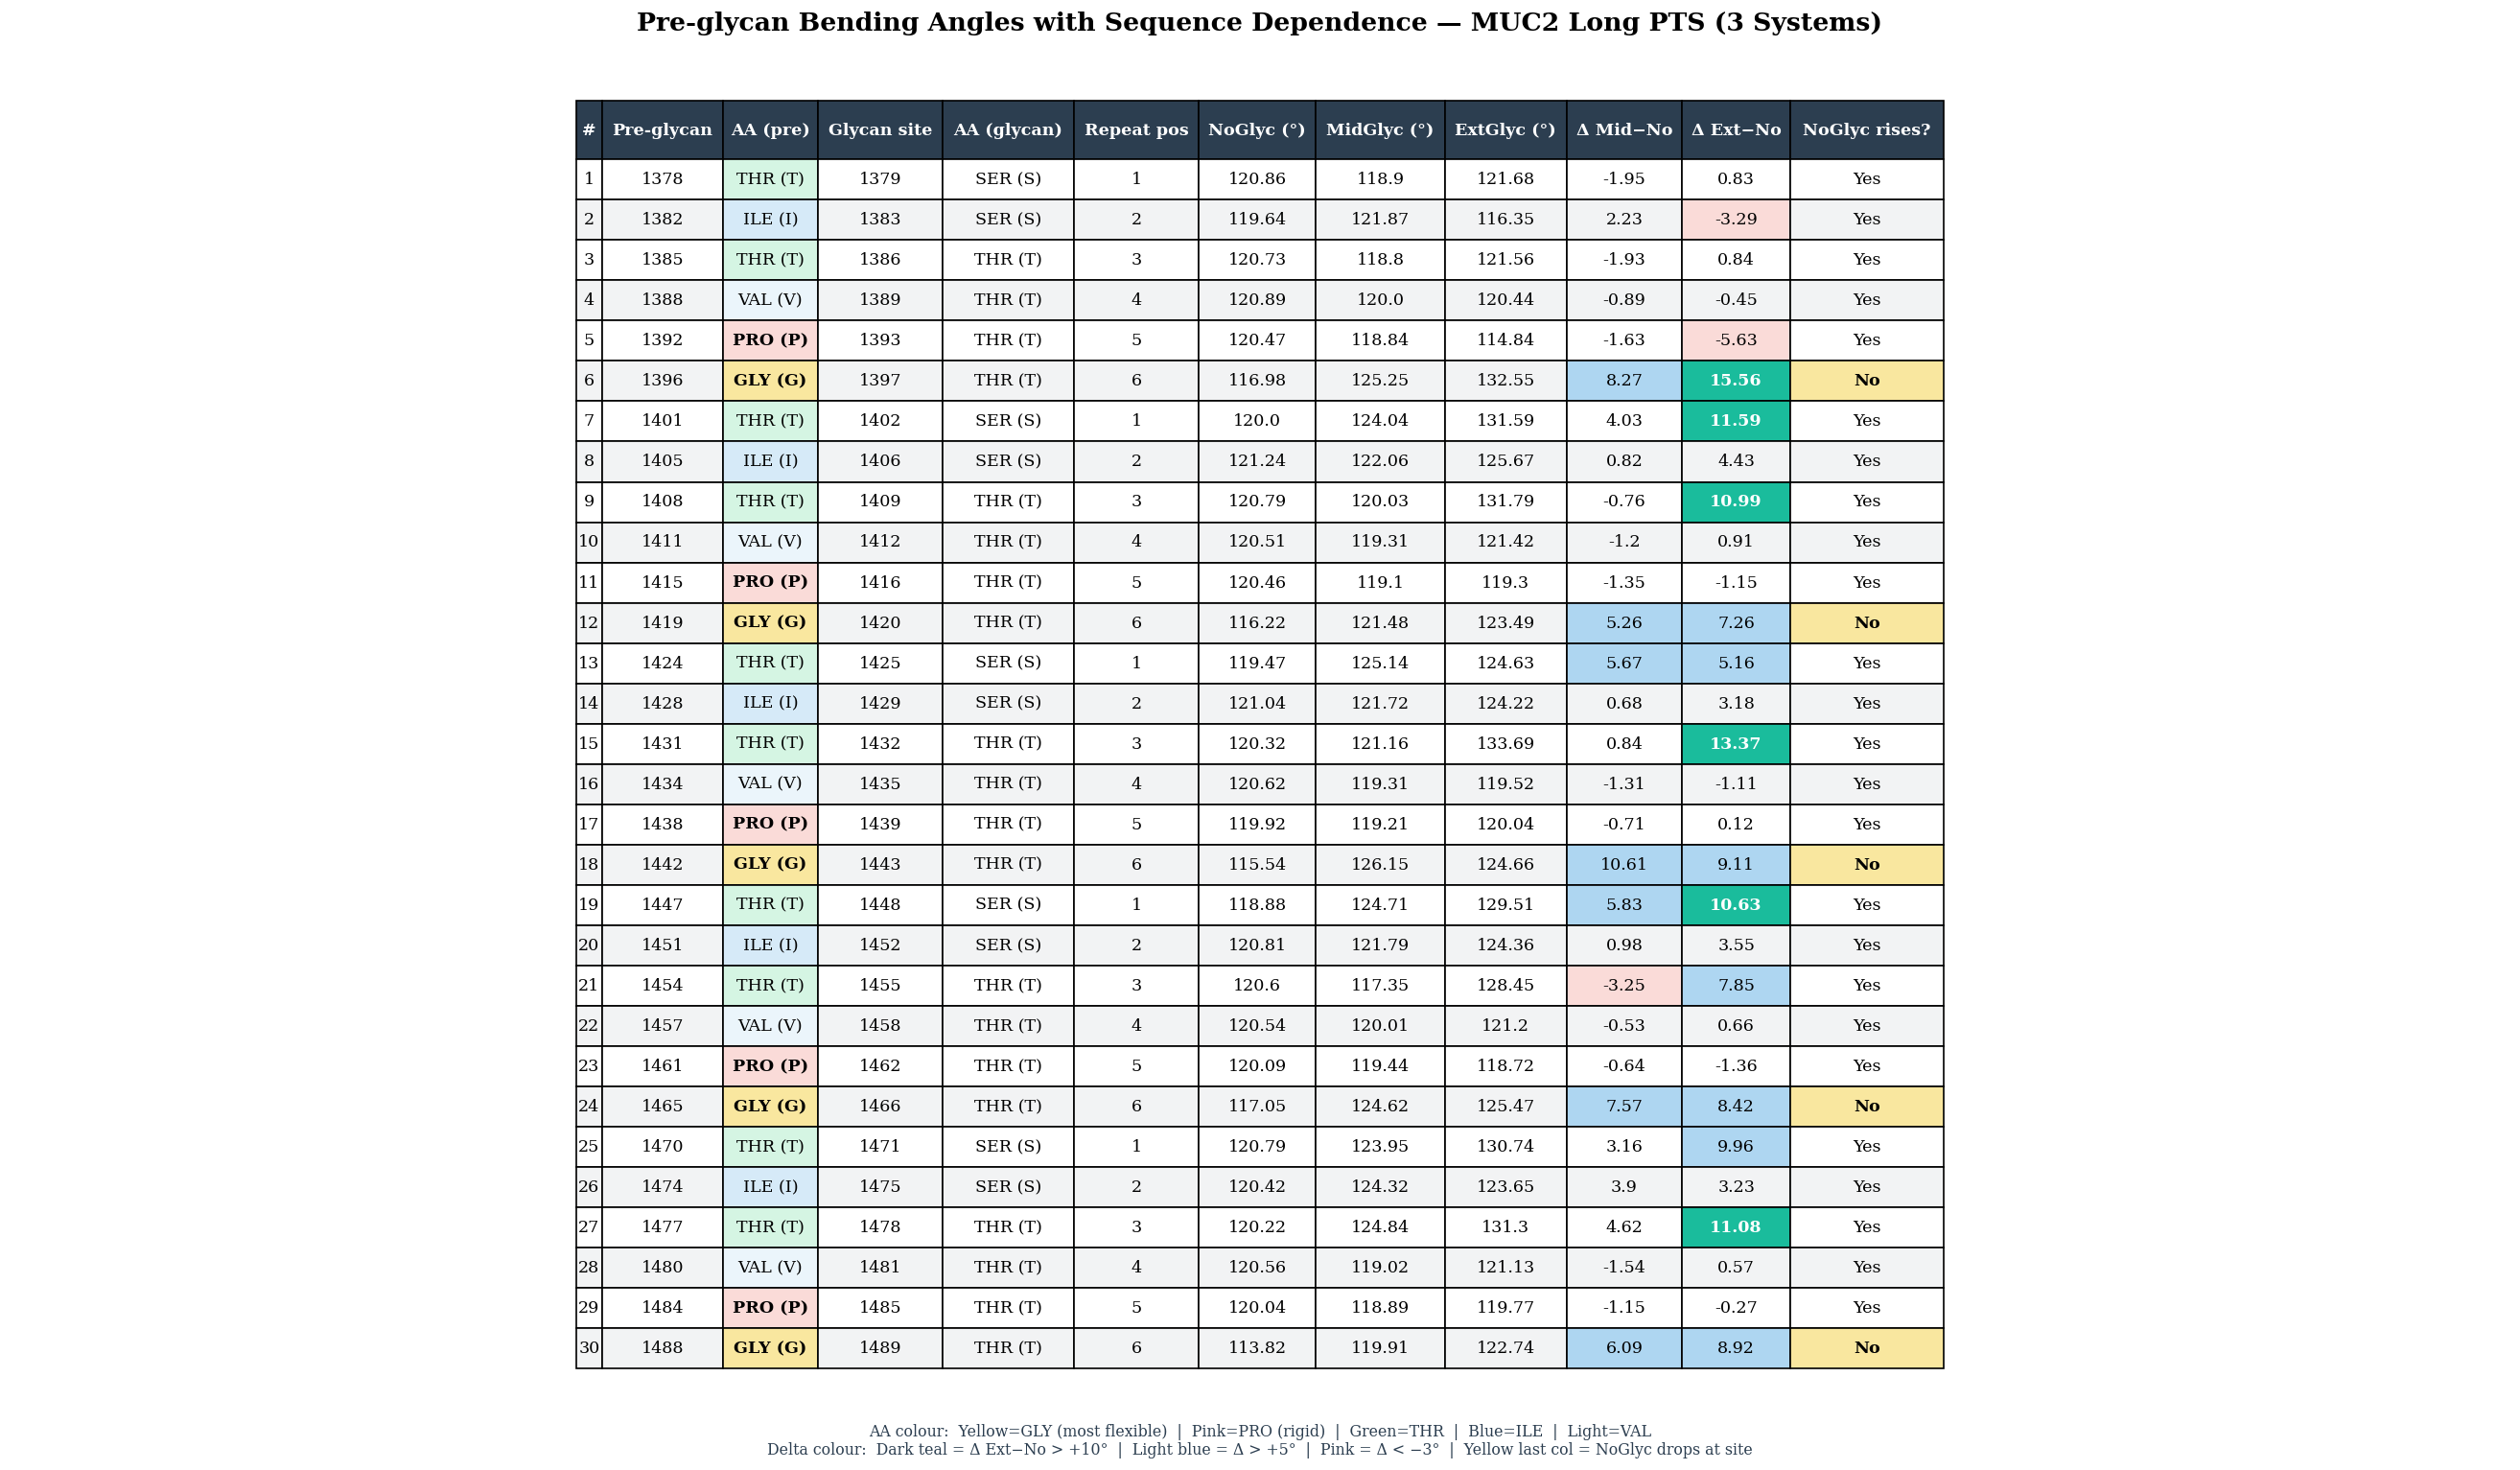

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/preglycan_sequence_dependence_table.png

Repeat unit summary (mean angles by position in 6-residue repeat):
Pos  AA    NoGlyc mean  MidGlyc mean  ExtGlyc mean
  1    THR       120.00        123.35        127.63
  2    ILE       120.63        122.35        122.85
  3    THR       120.53        120.44        129.36
  4    VAL       120.62        119.53        120.74
  5    PRO       120.20        119.10        118.53
  6    GLY       115.92        123.48        125.78


In [186]:
import pandas as pd

THREE_TO_ONE = {
    "ALA":"A","ARG":"R","ASN":"N","ASP":"D","CYS":"C","GLN":"Q","GLU":"E",
    "GLY":"G","HIS":"H","ILE":"I","LEU":"L","LYS":"K","MET":"M","PHE":"F",
    "PRO":"P","SER":"S","THR":"T","TRP":"W","TYR":"Y","VAL":"V",
    "HID":"H","HIE":"H","HIP":"H","CYX":"C"
}

# Sequence from PDB
pdb_path = "/home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/noglycans_mean.pdb"
seq = {}
with open(pdb_path) as fh:
    for line in fh:
        if line.startswith("ATOM") and line[12:16].strip() == "CA":
            seq[int(line[22:26])] = line[17:20].strip()

n_common = min(len(nog_prof), len(gly_prof), len(ext_prof))
res_nums = np.arange(n_common) + RES_OFFSET
kap_nog  = nog_prof[:n_common, 3]
kap_gly  = gly_prof[:n_common, 3]
kap_ext  = ext_prof[:n_common, 3]

pre_res = GLYCAN_RES - 1
pre_res = pre_res[(pre_res >= res_nums[0]) & (pre_res <= res_nums[-1])]

# AA background colours for sequence dependence
AA_CLR = {
    "GLY": "#F9E79F",   # yellow  — most flexible
    "PRO": "#FADBD8",   # pink    — rigid ring
    "THR": "#D5F5E3",   # green   — hydroxyl (glycan-like)
    "ILE": "#D6EAF8",   # blue    — hydrophobic
    "VAL": "#EBF5FB",   # light   — hydrophobic
}

rows = []
for i, (pr, pg) in enumerate(zip(pre_res, GLYCAN_RES), 1):
    idx  = pr - RES_OFFSET
    nog  = kap_nog[idx]
    gly  = kap_gly[idx]
    ext  = kap_ext[idx]
    aa3  = seq.get(pr, "???")
    aa1  = THREE_TO_ONE.get(aa3, "?")
    ga3  = seq.get(pg, "???")
    ga1  = THREE_TO_ONE.get(ga3, "?")
    rises = "Yes" if (idx > 0 and nog > kap_nog[idx-1]) else "No"
    pos_in_repeat = ((i-1) % 6) + 1
    rows.append({
        "#":              i,
        "Pre-glycan":     pr,
        "AA (pre)":       f"{aa3} ({aa1})",
        "Glycan site":    pg,
        "AA (glycan)":    f"{ga3} ({ga1})",
        "Repeat pos":     pos_in_repeat,
        "NoGlyc (°)":     round(nog, 2),
        "MidGlyc (°)":    round(gly, 2),
        "ExtGlyc (°)":    round(ext, 2),
        "Δ Mid−No":       round(gly - nog, 2),
        "Δ Ext−No":       round(ext - nog, 2),
        "NoGlyc rises?":  rises,
        "_aa3":           aa3,
    })

df = pd.DataFrame(rows)
display_cols = [c for c in df.columns if not c.startswith("_")]

fig, ax = plt.subplots(figsize=(22, 13), dpi=120)
fig.set_facecolor("white")
ax.axis("off")

tbl = ax.table(
    cellText=df[display_cols].values.tolist(),
    colLabels=display_cols,
    loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(10.5)
tbl.auto_set_column_width(col=list(range(len(display_cols))))

# Header
for j in range(len(display_cols)):
    cell = tbl[0, j]
    cell.set_facecolor("#2C3E50")
    cell.set_text_props(color="white", fontweight="bold",
                        fontfamily="DejaVu Serif", fontsize=10.5)
    cell.set_height(0.045)

for i, row in enumerate(rows, 1):
    aa3    = row["_aa3"]
    d_mid  = row["Δ Mid−No"]
    d_ext  = row["Δ Ext−No"]
    rises  = row["NoGlyc rises?"]
    base   = "#F2F3F4" if i % 2 == 0 else "white"
    aa_clr = AA_CLR.get(aa3, base)

    for j, col in enumerate(display_cols):
        cell = tbl[i, j]
        cell.set_height(0.031)
        cell.set_text_props(fontfamily="DejaVu Serif", fontsize=10.5)

        # AA column gets amino-acid colour
        if col == "AA (pre)":
            cell.set_facecolor(aa_clr)
            if aa3 in ("GLY", "PRO"):
                cell.set_text_props(fontfamily="DejaVu Serif", fontsize=10.5,
                                    fontweight="bold")
        elif col == "Δ Mid−No":
            if d_mid > 5:
                cell.set_facecolor("#AED6F1")
            elif d_mid < -3:
                cell.set_facecolor("#FADBD8")
            else:
                cell.set_facecolor(base)
        elif col == "Δ Ext−No":
            if d_ext > 10:
                cell.set_facecolor("#1ABC9C")
                cell.set_text_props(color="white", fontfamily="DejaVu Serif",
                                    fontsize=10.5, fontweight="bold")
            elif d_ext > 5:
                cell.set_facecolor("#AED6F1")
            elif d_ext < -3:
                cell.set_facecolor("#FADBD8")
            else:
                cell.set_facecolor(base)
        elif col == "NoGlyc rises?":
            if rises == "No":
                cell.set_facecolor("#F9E79F")
                cell.set_text_props(fontfamily="DejaVu Serif", fontsize=10.5,
                                    fontweight="bold")
            else:
                cell.set_facecolor(base)
        else:
            cell.set_facecolor(base)

fig.suptitle(
    "Pre-glycan Bending Angles with Sequence Dependence — MUC2 Long PTS (3 Systems)",
    fontsize=16, fontname="DejaVu Serif", fontweight="bold", y=0.97)

legend_txt = (
    "AA colour:  Yellow=GLY (most flexible)  |  Pink=PRO (rigid)  |  Green=THR  |  Blue=ILE  |  Light=VAL\n"
    "Delta colour:  Dark teal = Δ Ext−No > +10°  |  Light blue = Δ > +5°  |  Pink = Δ < −3°  |  Yellow last col = NoGlyc drops at site"
)
fig.text(0.5, 0.005, legend_txt, ha="center", fontsize=9.5,
         fontname="DejaVu Serif", color="#2C3E50")

plt.tight_layout(rect=[0, 0.04, 1, 0.96])
out = os.path.join(output_dir, "preglycan_sequence_dependence_table.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

# Print sequence repeat summary
print("\nRepeat unit summary (mean angles by position in 6-residue repeat):")
print(f"Pos  AA    NoGlyc mean  MidGlyc mean  ExtGlyc mean")
repeat_labels = ["THR","ILE","THR","VAL","PRO","GLY"]
for pos in range(1, 7):
    sub = [r for r in rows if r["Repeat pos"] == pos]
    m_no  = np.mean([r["NoGlyc (°)"]  for r in sub])
    m_gly = np.mean([r["MidGlyc (°)"] for r in sub])
    m_ext = np.mean([r["ExtGlyc (°)"] for r in sub])
    print(f"  {pos}    {repeat_labels[pos-1]:<4}  {m_no:>10.2f}   {m_gly:>11.2f}   {m_ext:>11.2f}")


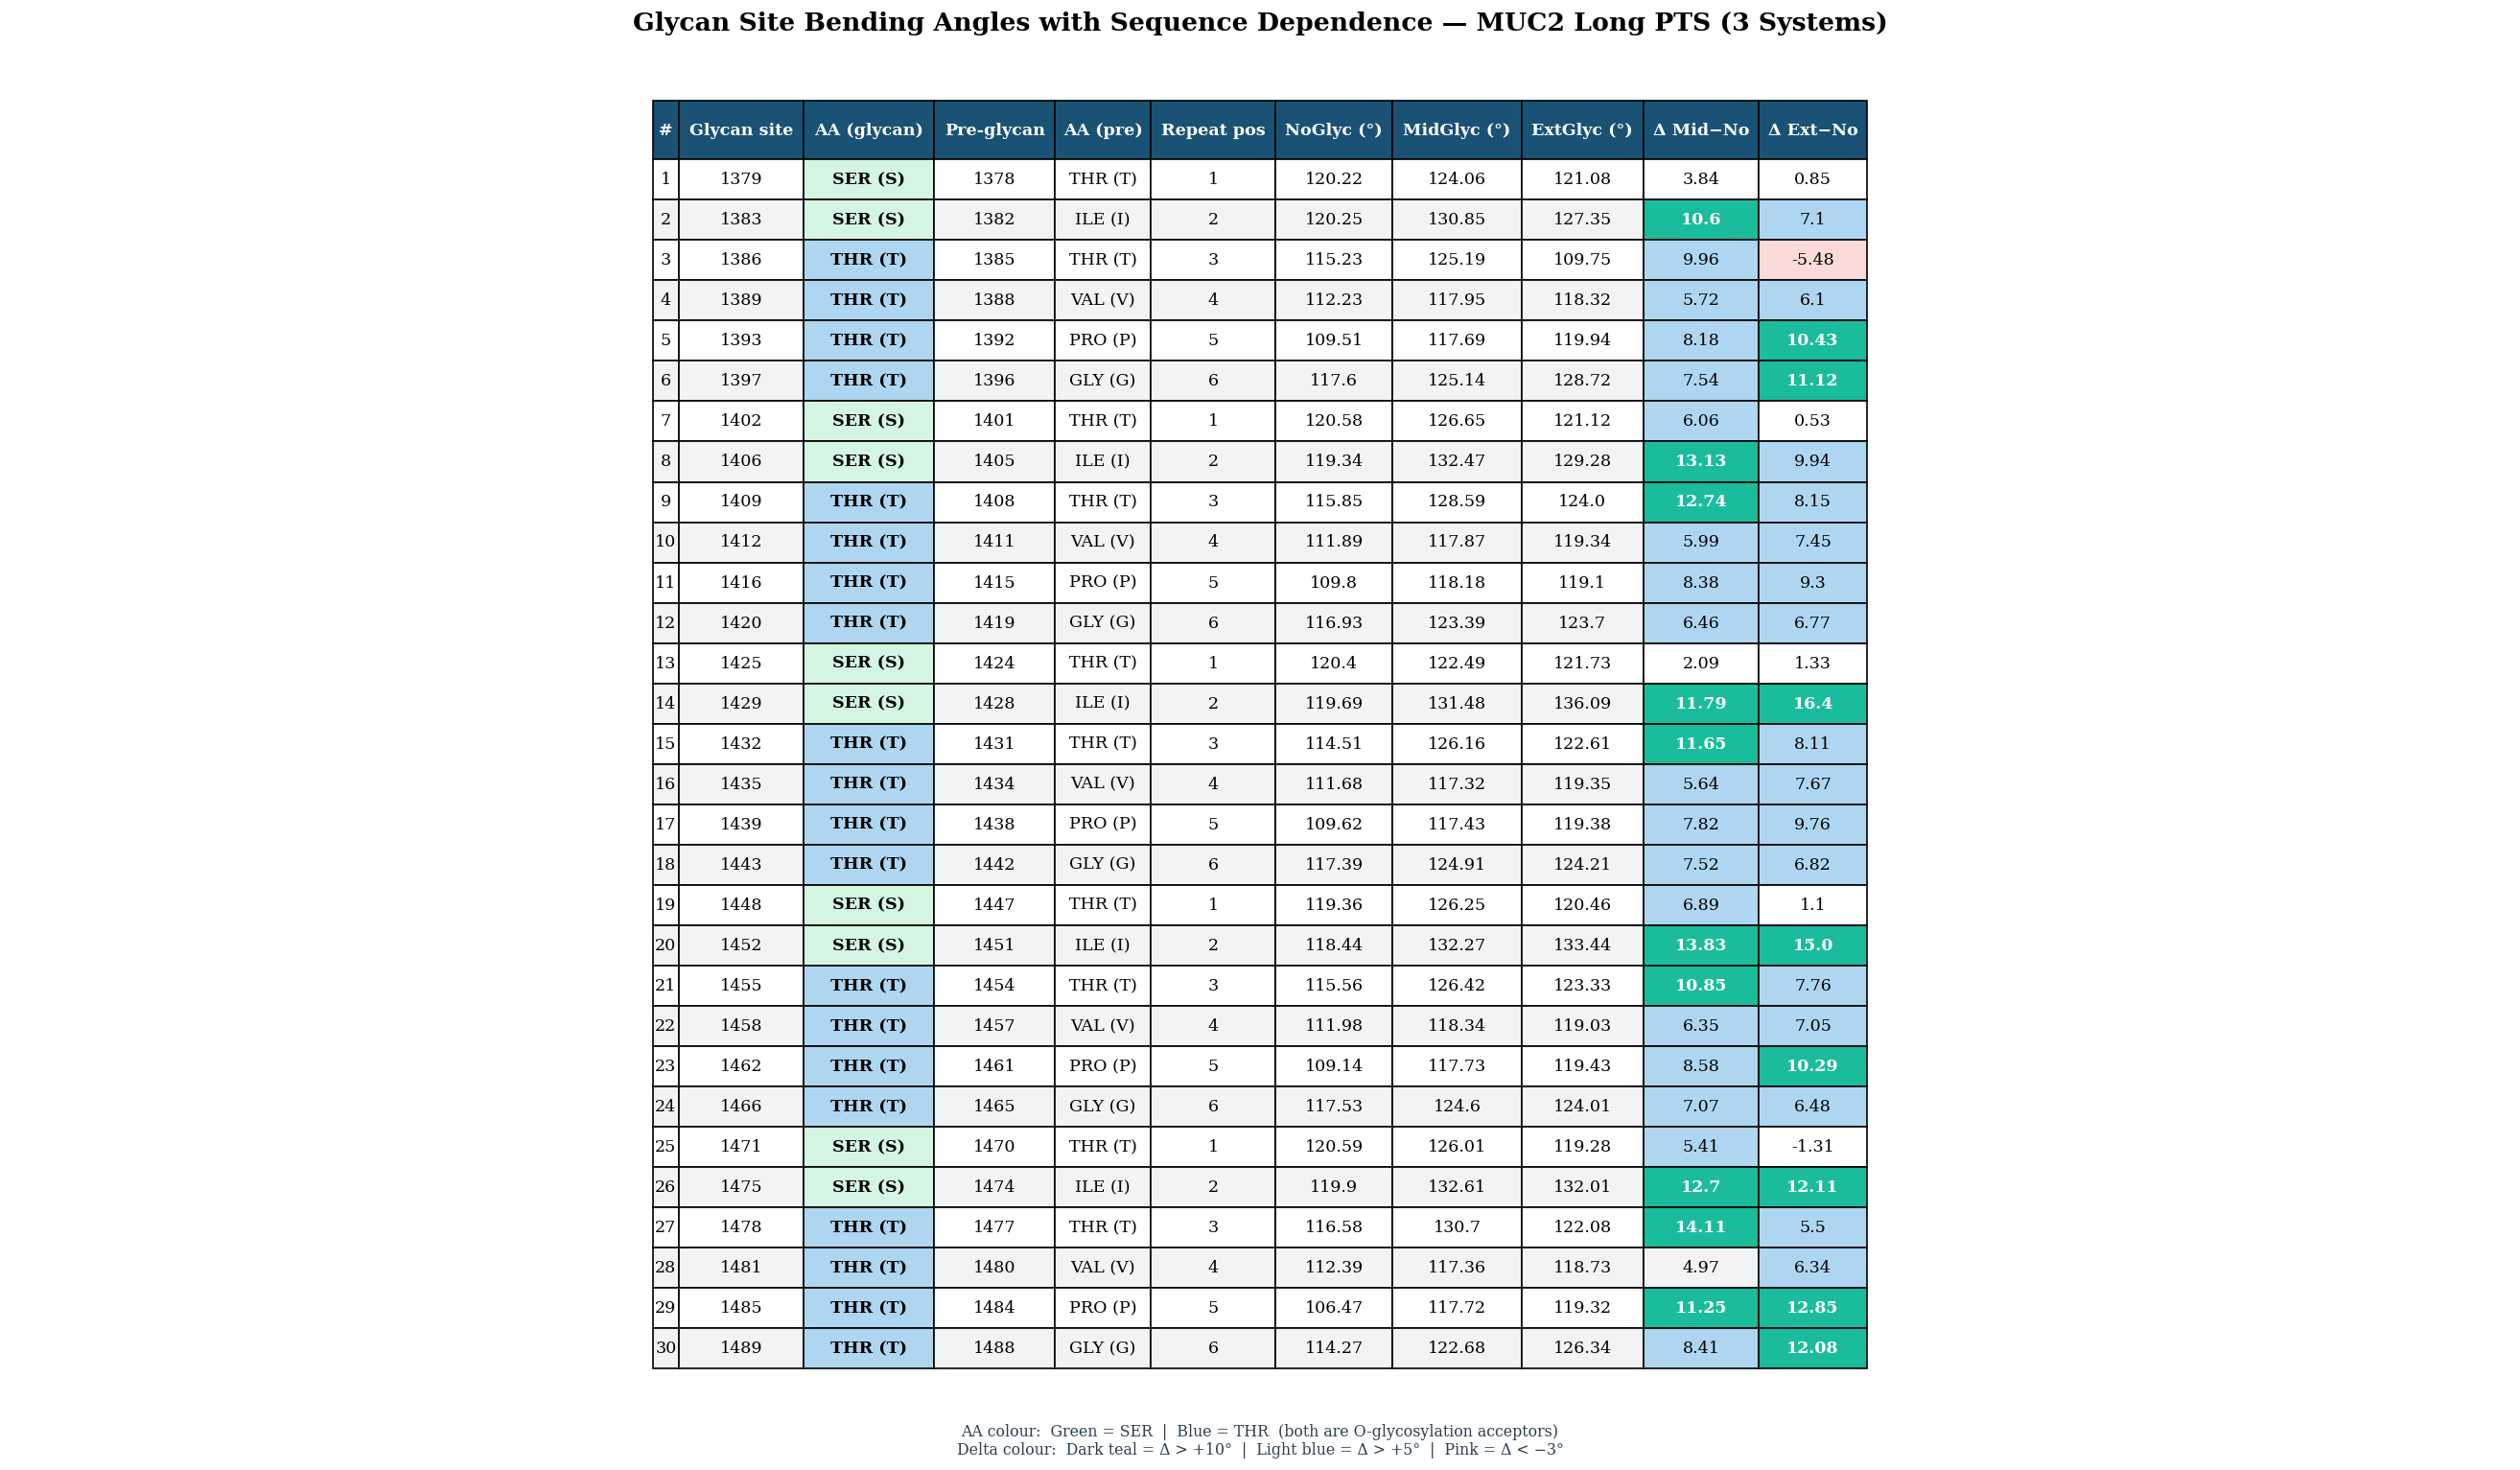

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/glycansite_sequence_dependence_table.png

Repeat unit summary at GLYCAN SITES (mean angles by position in 6-repeat):
  Pos 1  SER   NoGlyc=120.23  MidGlyc=125.09  ExtGlyc=120.73
  Pos 2  SER   NoGlyc=119.52  MidGlyc=131.94  ExtGlyc=131.63
  Pos 3  THR   NoGlyc=115.55  MidGlyc=127.41  ExtGlyc=120.35
  Pos 4  THR   NoGlyc=112.03  MidGlyc=117.77  ExtGlyc=118.95
  Pos 5  THR   NoGlyc=108.91  MidGlyc=117.75  ExtGlyc=119.43
  Pos 6  THR   NoGlyc=116.74  MidGlyc=124.14  ExtGlyc=125.40


In [187]:
import pandas as pd

THREE_TO_ONE = {
    "ALA":"A","ARG":"R","ASN":"N","ASP":"D","CYS":"C","GLN":"Q","GLU":"E",
    "GLY":"G","HIS":"H","ILE":"I","LEU":"L","LYS":"K","MET":"M","PHE":"F",
    "PRO":"P","SER":"S","THR":"T","TRP":"W","TYR":"Y","VAL":"V",
    "HID":"H","HIE":"H","HIP":"H","CYX":"C"
}

pdb_path = "/home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/noglycans_mean.pdb"
seq = {}
with open(pdb_path) as fh:
    for line in fh:
        if line.startswith("ATOM") and line[12:16].strip() == "CA":
            seq[int(line[22:26])] = line[17:20].strip()

n_common = min(len(nog_prof), len(gly_prof), len(ext_prof))
res_nums = np.arange(n_common) + RES_OFFSET
kap_nog  = nog_prof[:n_common, 3]
kap_gly  = gly_prof[:n_common, 3]
kap_ext  = ext_prof[:n_common, 3]

glycan_in_range = GLYCAN_RES[(GLYCAN_RES >= res_nums[0]) & (GLYCAN_RES <= res_nums[-1])]
pre_in_range    = glycan_in_range - 1

AA_CLR = {
    "SER": "#D5F5E3",
    "THR": "#AED6F1",
}

rows = []
for i, (gr, pr) in enumerate(zip(glycan_in_range, pre_in_range), 1):
    gi   = gr - RES_OFFSET
    nog  = kap_nog[gi]
    gly  = kap_gly[gi]
    ext  = kap_ext[gi]
    aa3  = seq.get(gr, "???")
    aa1  = THREE_TO_ONE.get(aa3, "?")
    pa3  = seq.get(pr, "???")
    pa1  = THREE_TO_ONE.get(pa3, "?")
    pos_in_repeat = ((i-1) % 6) + 1
    rows.append({
        "#":              i,
        "Glycan site":    gr,
        "AA (glycan)":    f"{aa3} ({aa1})",
        "Pre-glycan":     pr,
        "AA (pre)":       f"{pa3} ({pa1})",
        "Repeat pos":     pos_in_repeat,
        "NoGlyc (°)":     round(nog, 2),
        "MidGlyc (°)":    round(gly, 2),
        "ExtGlyc (°)":    round(ext, 2),
        "Δ Mid−No":       round(gly - nog, 2),
        "Δ Ext−No":       round(ext - nog, 2),
        "_aa3":           aa3,
    })

df = pd.DataFrame(rows)
display_cols = [c for c in df.columns if not c.startswith("_")]

fig, ax = plt.subplots(figsize=(22, 13), dpi=120)
fig.set_facecolor("white")
ax.axis("off")

tbl = ax.table(
    cellText=df[display_cols].values.tolist(),
    colLabels=display_cols,
    loc="center", cellLoc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(10.5)
tbl.auto_set_column_width(col=list(range(len(display_cols))))

for j in range(len(display_cols)):
    cell = tbl[0, j]
    cell.set_facecolor("#1A5276")
    cell.set_text_props(color="white", fontweight="bold",
                        fontfamily="DejaVu Serif", fontsize=10.5)
    cell.set_height(0.045)

for i, row in enumerate(rows, 1):
    aa3   = row["_aa3"]
    d_mid = row["Δ Mid−No"]
    d_ext = row["Δ Ext−No"]
    base  = "#F2F3F4" if i % 2 == 0 else "white"
    aa_clr = AA_CLR.get(aa3, base)

    for j, col in enumerate(display_cols):
        cell = tbl[i, j]
        cell.set_height(0.031)
        cell.set_text_props(fontfamily="DejaVu Serif", fontsize=10.5)

        if col == "AA (glycan)":
            cell.set_facecolor(aa_clr)
            cell.set_text_props(fontfamily="DejaVu Serif", fontsize=10.5,
                                fontweight="bold")
        elif col == "Δ Mid−No":
            if d_mid > 10:
                cell.set_facecolor("#1ABC9C")
                cell.set_text_props(color="white", fontfamily="DejaVu Serif",
                                    fontsize=10.5, fontweight="bold")
            elif d_mid > 5:
                cell.set_facecolor("#AED6F1")
            elif d_mid < -3:
                cell.set_facecolor("#FADBD8")
            else:
                cell.set_facecolor(base)
        elif col == "Δ Ext−No":
            if d_ext > 10:
                cell.set_facecolor("#1ABC9C")
                cell.set_text_props(color="white", fontfamily="DejaVu Serif",
                                    fontsize=10.5, fontweight="bold")
            elif d_ext > 5:
                cell.set_facecolor("#AED6F1")
            elif d_ext < -3:
                cell.set_facecolor("#FADBD8")
            else:
                cell.set_facecolor(base)
        else:
            cell.set_facecolor(base)

fig.suptitle(
    "Glycan Site Bending Angles with Sequence Dependence — MUC2 Long PTS (3 Systems)",
    fontsize=16, fontname="DejaVu Serif", fontweight="bold", y=0.97)

legend_txt = (
    "AA colour:  Green = SER  |  Blue = THR  (both are O-glycosylation acceptors)\n"
    "Delta colour:  Dark teal = Δ > +10°  |  Light blue = Δ > +5°  |  Pink = Δ < −3°"
)
fig.text(0.5, 0.005, legend_txt, ha="center", fontsize=9.5,
         fontname="DejaVu Serif", color="#2C3E50")

plt.tight_layout(rect=[0, 0.04, 1, 0.96])
out = os.path.join(output_dir, "glycansite_sequence_dependence_table.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

print("\nRepeat unit summary at GLYCAN SITES (mean angles by position in 6-repeat):")
repeat_labels_g = ["SER","SER","THR","THR","THR","THR"]
for pos in range(1, 7):
    sub = [r for r in rows if r["Repeat pos"] == pos]
    m_no  = np.mean([r["NoGlyc (°)"]  for r in sub])
    m_gly = np.mean([r["MidGlyc (°)"] for r in sub])
    m_ext = np.mean([r["ExtGlyc (°)"] for r in sub])
    print(f"  Pos {pos}  {repeat_labels_g[pos-1]:<4}  NoGlyc={m_no:.2f}  MidGlyc={m_gly:.2f}  ExtGlyc={m_ext:.2f}")


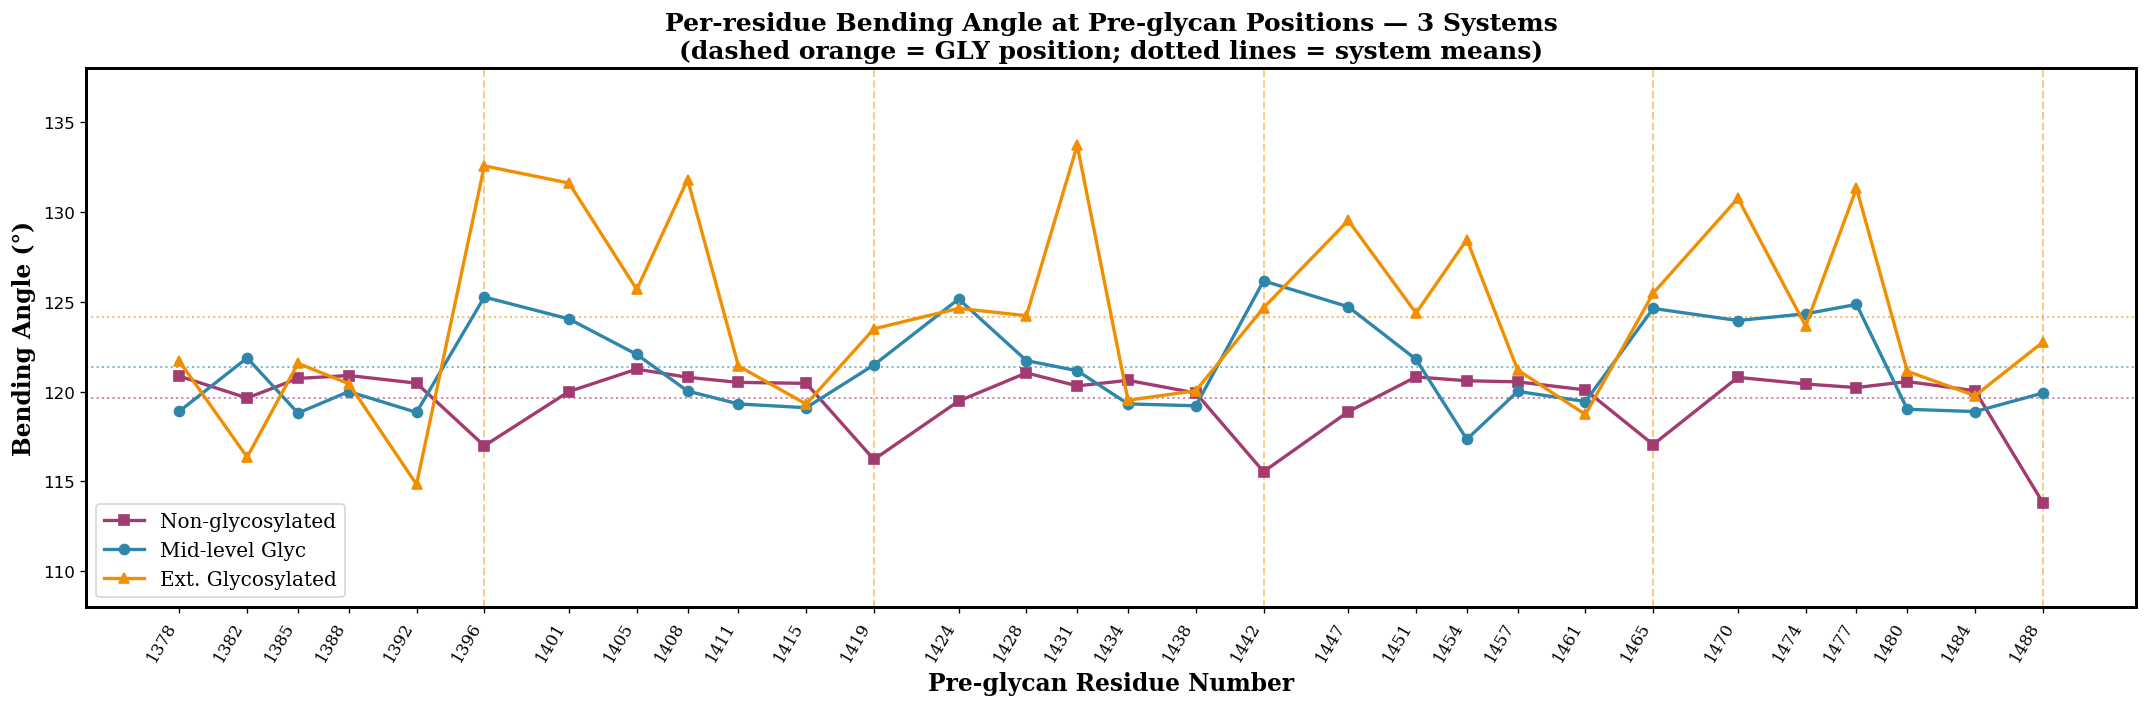

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/preglycan_perres_lineplot.png


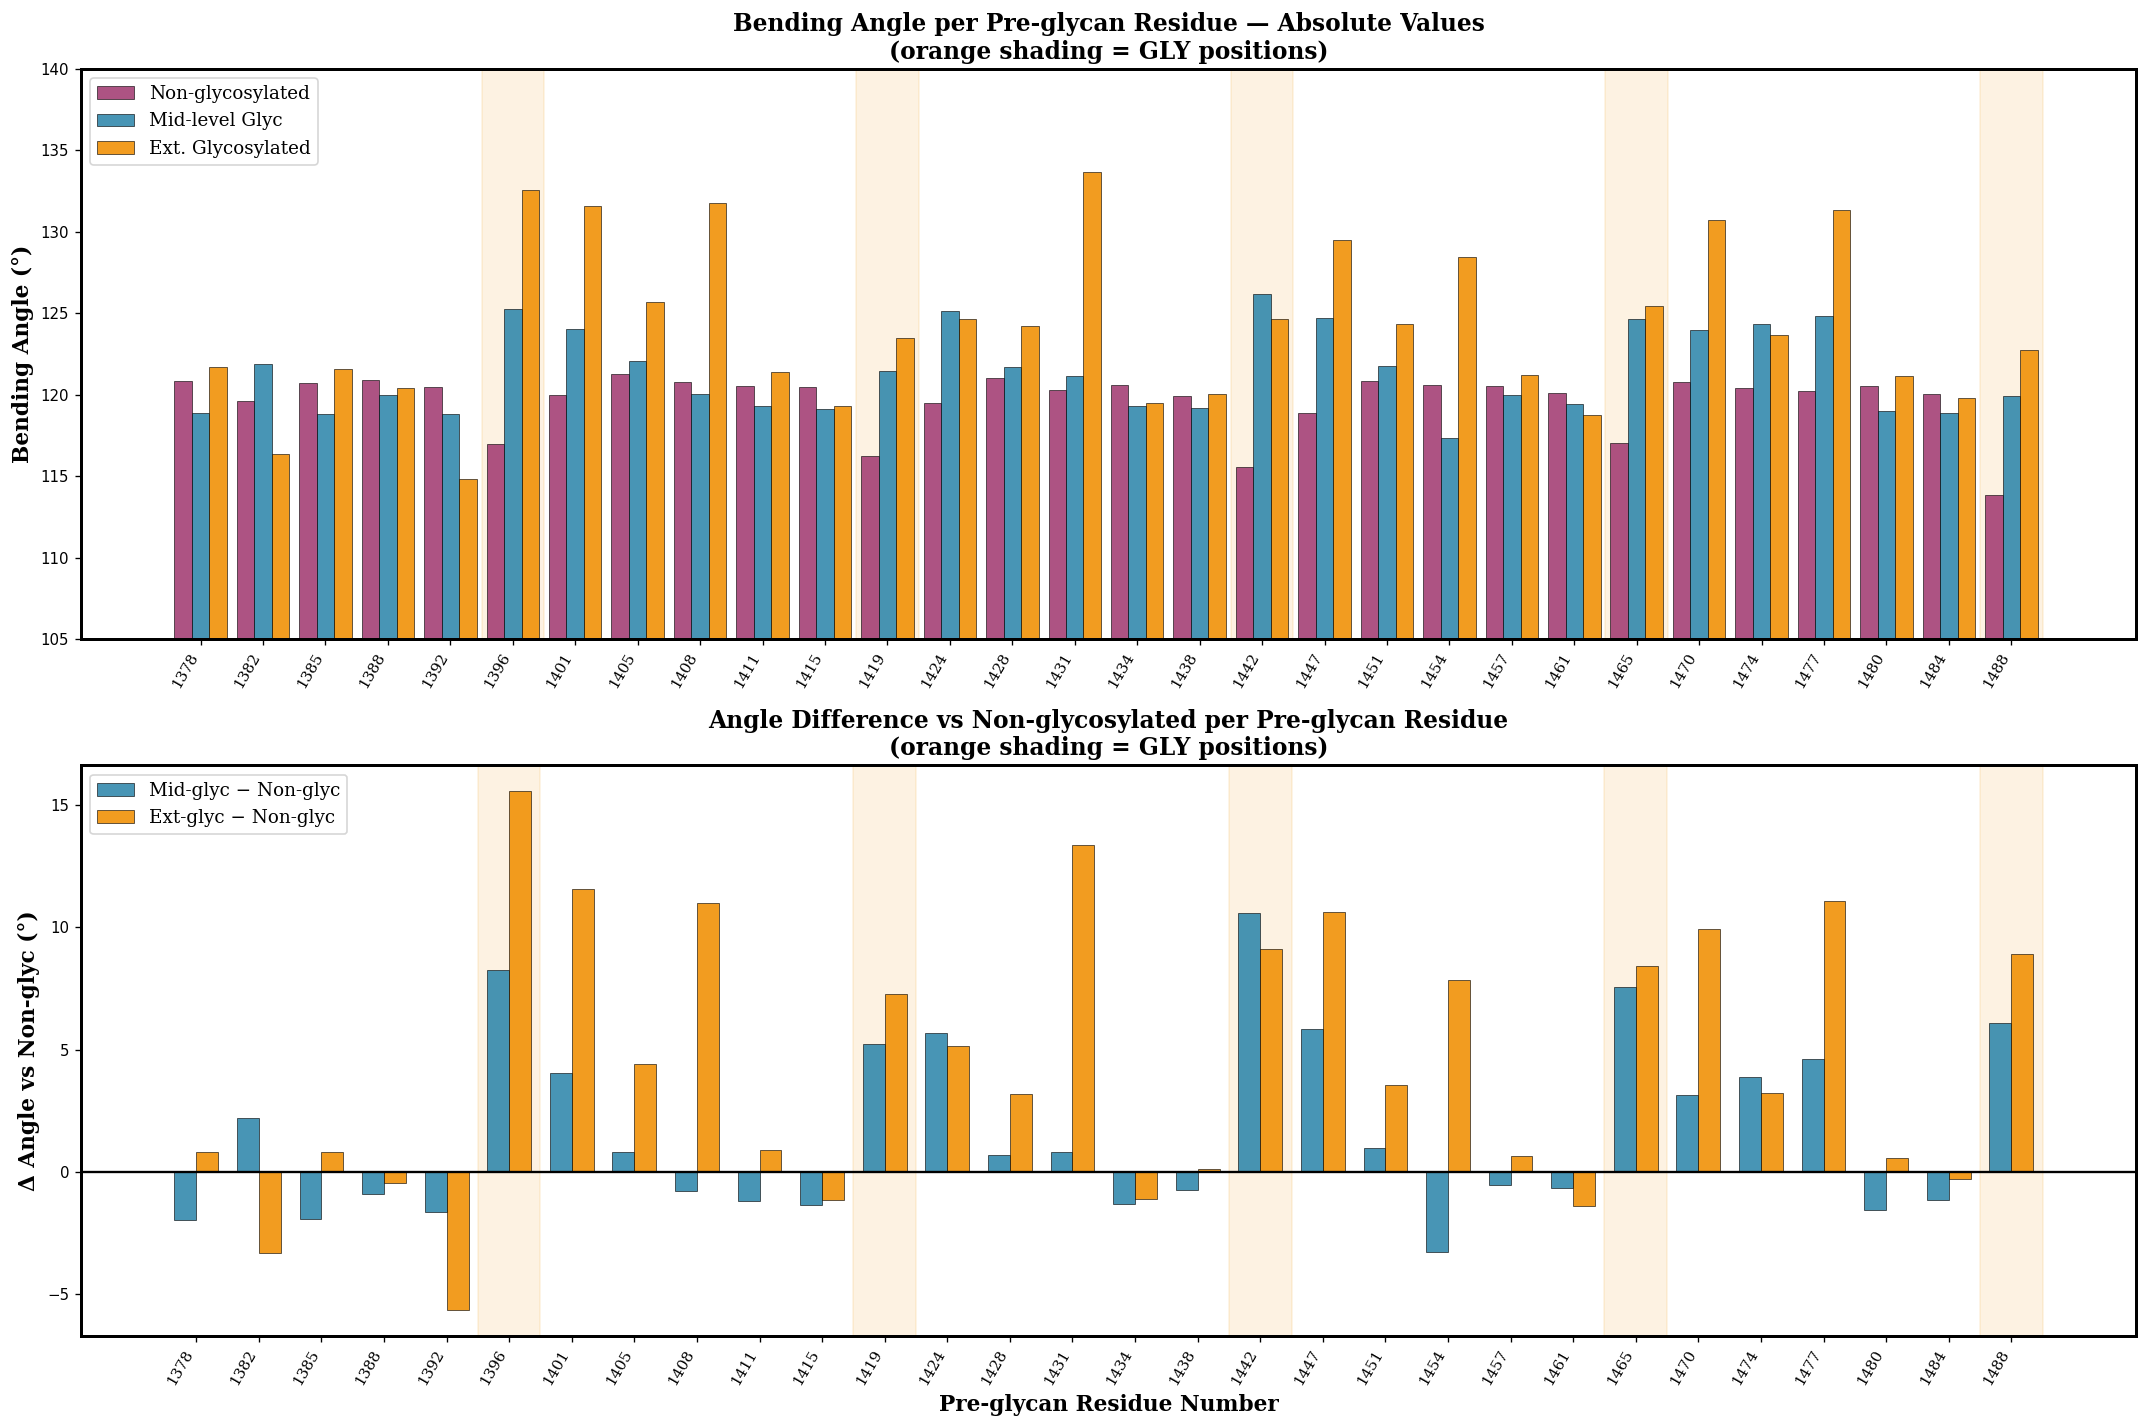

Saved: /home/computer2/analysis_simulations/analysis/radius_of_curvature/plots/preglycan_perres_bargraph.png


In [188]:
# ----------------------------------------------------------------
# Per-residue bending angle: line plot + bar chart for pre-glycan
# ----------------------------------------------------------------
n_common = min(len(nog_prof), len(gly_prof), len(ext_prof))
res_nums = np.arange(n_common) + RES_OFFSET
kap_nog  = nog_prof[:n_common, 3]
kap_gly  = gly_prof[:n_common, 3]
kap_ext  = ext_prof[:n_common, 3]

pre_res = GLYCAN_RES - 1
pre_res = pre_res[(pre_res >= res_nums[0]) & (pre_res <= res_nums[-1])]
pre_idx = pre_res - RES_OFFSET

nog_pre = kap_nog[pre_idx]
gly_pre = kap_gly[pre_idx]
ext_pre = kap_ext[pre_idx]

x = np.arange(len(pre_res))

# ---- Figure 1: Line plot (per-residue overlay) ----
fig, ax = plt.subplots(figsize=(18, 6), dpi=120)
fig.set_facecolor("white")

ax.plot(pre_res, nog_pre, color=CLR_NOG, linewidth=2.0, marker="s",
        markersize=6, label="Non-glycosylated", zorder=3)
ax.plot(pre_res, gly_pre, color=CLR_GLY, linewidth=2.0, marker="o",
        markersize=6, label="Mid-level Glyc", zorder=3)
ax.plot(pre_res, ext_pre, color=CLR_EXT, linewidth=2.0, marker="^",
        markersize=6, label="Ext. Glycosylated", zorder=3)

# Mark GLY positions (every 6th pre-glycan)
gly_mask = np.array([(i % 6 == 5) for i in range(len(pre_res))])
for pr in pre_res[gly_mask]:
    ax.axvline(pr, color="#F39C12", linewidth=1.2, linestyle="--",
               alpha=0.5, zorder=1)

ax.axhline(nog_pre.mean(), color=CLR_NOG, linewidth=1.2, linestyle=":",
           alpha=0.6)
ax.axhline(gly_pre.mean(), color=CLR_GLY, linewidth=1.2, linestyle=":",
           alpha=0.6)
ax.axhline(ext_pre.mean(), color=CLR_EXT, linewidth=1.2, linestyle=":",
           alpha=0.6)

ax.set_xticks(pre_res)
ax.set_xticklabels(pre_res, rotation=60, ha="right", fontsize=9,
                   fontname="DejaVu Serif")
ax.set_xlabel("Pre-glycan Residue Number", fontsize=14,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Bending Angle (°)", fontsize=14,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title(
    "Per-residue Bending Angle at Pre-glycan Positions — 3 Systems\n"
    "(dashed orange = GLY position; dotted lines = system means)",
    fontsize=15, fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=12, prop={"family":"DejaVu Serif","size":12},
          loc="lower left")
ax.tick_params(labelsize=10)
ax.set_ylim(108, 138)
for sp in ax.spines.values(): sp.set_linewidth(1.8)
plt.tight_layout()
out1 = os.path.join(output_dir, "preglycan_perres_lineplot.png")
plt.savefig(out1, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out1}")

# ---- Figure 2: Grouped bar chart (per-residue) ----
fig, axes = plt.subplots(2, 1, figsize=(18, 12), dpi=120)
fig.set_facecolor("white")

# Top panel: absolute angles
ax = axes[0]
w = 0.28
ax.bar(x - w, nog_pre, width=w, color=CLR_NOG, alpha=0.88,
       edgecolor="black", linewidth=0.4, label="Non-glycosylated")
ax.bar(x,     gly_pre, width=w, color=CLR_GLY, alpha=0.88,
       edgecolor="black", linewidth=0.4, label="Mid-level Glyc")
ax.bar(x + w, ext_pre, width=w, color=CLR_EXT, alpha=0.88,
       edgecolor="black", linewidth=0.4, label="Ext. Glycosylated")
for i in range(len(pre_res)):
    if i % 6 == 5:
        ax.axvspan(i - 0.5, i + 0.5, color="#F39C12", alpha=0.12, zorder=0)
ax.set_xticks(x)
ax.set_xticklabels(pre_res, rotation=60, ha="right", fontsize=9,
                   fontname="DejaVu Serif")
ax.set_ylabel("Bending Angle (°)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Bending Angle per Pre-glycan Residue — Absolute Values\n"
             "(orange shading = GLY positions)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=11, prop={"family":"DejaVu Serif","size":11})
ax.set_ylim(105, 140)
ax.tick_params(labelsize=9)
for sp in ax.spines.values(): sp.set_linewidth(1.8)

# Bottom panel: differences vs non-glyc
ax = axes[1]
diff_mid = gly_pre - nog_pre
diff_ext = ext_pre - nog_pre
w2 = 0.35
ax.bar(x - w2/2, diff_mid, width=w2, color=CLR_GLY, alpha=0.88,
       edgecolor="black", linewidth=0.4, label="Mid-glyc − Non-glyc")
ax.bar(x + w2/2, diff_ext, width=w2, color=CLR_EXT, alpha=0.88,
       edgecolor="black", linewidth=0.4, label="Ext-glyc − Non-glyc")
ax.axhline(0, color="black", linewidth=1.4)
for i in range(len(pre_res)):
    if i % 6 == 5:
        ax.axvspan(i - 0.5, i + 0.5, color="#F39C12", alpha=0.12, zorder=0)
ax.set_xticks(x)
ax.set_xticklabels(pre_res, rotation=60, ha="right", fontsize=9,
                   fontname="DejaVu Serif")
ax.set_xlabel("Pre-glycan Residue Number", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Δ Angle vs Non-glyc (°)", fontsize=13,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Angle Difference vs Non-glycosylated per Pre-glycan Residue\n"
             "(orange shading = GLY positions)",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold")
ax.legend(fontsize=11, prop={"family":"DejaVu Serif","size":11})
ax.tick_params(labelsize=9)
for sp in ax.spines.values(): sp.set_linewidth(1.8)

plt.tight_layout()
out2 = os.path.join(output_dir, "preglycan_perres_bargraph.png")
plt.savefig(out2, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out2}")


In [ ]:
# ── Grouped bar chart with residue numbers annotated on bars ──────────────
import numpy as np
import matplotlib.pyplot as plt

n_common = min(len(nog_prof), len(gly_prof), len(ext_prof))
res_nums  = np.arange(n_common) + RES_OFFSET
kap_nog   = nog_prof[:n_common, 3]
kap_gly   = gly_prof[:n_common, 3]
kap_ext   = ext_prof[:n_common, 3]

pre_res = GLYCAN_RES - 1
pre_res = pre_res[(pre_res >= res_nums[0]) & (pre_res <= res_nums[-1])]
pre_idx = pre_res - RES_OFFSET

nog_pre = kap_nog[pre_idx]
gly_pre = kap_gly[pre_idx]
ext_pre = kap_ext[pre_idx]
diff_mid = gly_pre - nog_pre
diff_ext = ext_pre - nog_pre

x   = np.arange(len(pre_res))
w   = 0.28
w2  = 0.35

# Amino acid lookup for bar labels
THREE_TO_ONE = {'THR':'T','ILE':'I','VAL':'V','PRO':'P','GLY':'G',
                'SER':'S','ALA':'A'}
seq_aa = {}
pdb_path = '/home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/noglycans_mean.pdb'
with open(pdb_path) as fh:
    for line in fh:
        if line.startswith('ATOM') and line[12:16].strip() == 'CA':
            seq_aa[int(line[22:26])] = line[17:20].strip()

fig, axes = plt.subplots(2, 1, figsize=(20, 14), dpi=120)
fig.set_facecolor('white')

# ── Top panel: absolute angles ────────────────────────────────────────────
ax = axes[0]
bars_nog = ax.bar(x - w, nog_pre, width=w, color=CLR_NOG, alpha=0.88,
                  edgecolor='black', linewidth=0.4, label='Non-glycosylated')
bars_gly = ax.bar(x,     gly_pre, width=w, color=CLR_GLY, alpha=0.88,
                  edgecolor='black', linewidth=0.4, label='Mid-level Glyc')
bars_ext = ax.bar(x + w, ext_pre, width=w, color=CLR_EXT, alpha=0.88,
                  edgecolor='black', linewidth=0.4, label='Ext. Glycosylated')

for i in range(len(pre_res)):
    if i % 6 == 5:
        ax.axvspan(i - 0.5, i + 0.5, color='#F39C12', alpha=0.12, zorder=0)

# Annotate residue number + AA on top of each group
for i, pr in enumerate(pre_res):
    aa3 = seq_aa.get(pr, '???')
    aa1 = THREE_TO_ONE.get(aa3, '?')
    top = max(nog_pre[i], gly_pre[i], ext_pre[i]) + 0.3
    label = f'{pr}\n{aa3}'
    ax.text(x[i], top, label, ha='center', va='bottom',
            fontsize=6.5, fontfamily='DejaVu Serif',
            fontweight='bold' if aa3 == 'GLY' else 'normal',
            color='#E67E22' if aa3 == 'GLY' else '#2C3E50',
            rotation=0)

ax.set_xticks(x)
ax.set_xticklabels([str(r) for r in pre_res], rotation=60, ha='right',
                   fontsize=8, fontfamily='DejaVu Serif')
ax.set_ylabel('Bending Angle (°)', fontsize=13,
              fontfamily='DejaVu Serif', fontweight='bold')
ax.set_title(
    'Bending Angle per Pre-glycan Residue — Absolute Values\n'
    '(residue number + amino acid above each group; orange = GLY)',
    fontsize=14, fontfamily='DejaVu Serif', fontweight='bold')
ax.legend(fontsize=11, prop={'family':'DejaVu Serif','size':11})
ax.set_ylim(105, 145)
ax.tick_params(labelsize=9)
for sp in ax.spines.values(): sp.set_linewidth(1.8)

# ── Bottom panel: differences vs non-glyc ────────────────────────────────
ax = axes[1]
ax.bar(x - w2/2, diff_mid, width=w2, color=CLR_GLY, alpha=0.88,
       edgecolor='black', linewidth=0.4, label='Mid-glyc − Non-glyc')
ax.bar(x + w2/2, diff_ext, width=w2, color=CLR_EXT, alpha=0.88,
       edgecolor='black', linewidth=0.4, label='Ext-glyc − Non-glyc')
ax.axhline(0, color='black', linewidth=1.4)

for i in range(len(pre_res)):
    if i % 6 == 5:
        ax.axvspan(i - 0.5, i + 0.5, color='#F39C12', alpha=0.12, zorder=0)

# Annotate residue number + AA below x-axis line of each group
ymin = min(diff_mid.min(), diff_ext.min())
for i, pr in enumerate(pre_res):
    aa3 = seq_aa.get(pr, '???')
    label = f'{pr}\n{aa3}'
    # place label above or below zero depending on bar direction
    d_sign = (diff_mid[i] + diff_ext[i]) / 2
    if d_sign >= 0:
        ytxt = max(diff_mid[i], diff_ext[i]) + 0.2
        va = 'bottom'
    else:
        ytxt = min(diff_mid[i], diff_ext[i]) - 0.2
        va = 'top'
    ax.text(x[i], ytxt, label, ha='center', va=va,
            fontsize=6.5, fontfamily='DejaVu Serif',
            fontweight='bold' if aa3 == 'GLY' else 'normal',
            color='#E67E22' if aa3 == 'GLY' else '#2C3E50')

ax.set_xticks(x)
ax.set_xticklabels([str(r) for r in pre_res], rotation=60, ha='right',
                   fontsize=8, fontfamily='DejaVu Serif')
ax.set_xlabel('Pre-glycan Residue Number', fontsize=13,
              fontfamily='DejaVu Serif', fontweight='bold')
ax.set_ylabel('Δ Angle vs Non-glyc (°)', fontsize=13,
              fontfamily='DejaVu Serif', fontweight='bold')
ax.set_title(
    'Angle Difference vs Non-glycosylated per Pre-glycan Residue\n'
    '(residue number + amino acid above/below each group; orange = GLY)',
    fontsize=14, fontfamily='DejaVu Serif', fontweight='bold')
ax.legend(fontsize=11, prop={'family':'DejaVu Serif','size':11})
ax.tick_params(labelsize=9)
for sp in ax.spines.values(): sp.set_linewidth(1.8)

plt.tight_layout()
out = os.path.join(output_dir, 'preglycan_perres_bargraph_labeled.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved: {out}')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ── Data ─────────────────────────────────────────────────────────────────────
n_common = min(len(nog_prof), len(gly_prof), len(ext_prof))
res_nums  = np.arange(n_common) + RES_OFFSET
kap_nog   = nog_prof[:n_common, 3]
kap_gly   = gly_prof[:n_common, 3]
kap_ext   = ext_prof[:n_common, 3]

pre_res = GLYCAN_RES - 1
pre_res = pre_res[(pre_res >= res_nums[0]) & (pre_res <= res_nums[-1])]

# ── Amino acid lookup ────────────────────────────────────────────────────────
seq = {}
pdb_path = '/home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/noglycans_mean.pdb'
with open(pdb_path) as fh:
    for line in fh:
        if line.startswith('ATOM') and line[12:16].strip() == 'CA':
            seq[int(line[22:26])] = line[17:20].strip()

THREE_TO_ONE = {'THR':'T','ILE':'I','VAL':'V','PRO':'P','GLY':'G','SER':'S','ALA':'A'}
AA_CLR = {'GLY':'#FDEBD0','PRO':'#FADBD8','THR':'#D5F5E3','ILE':'#D6EAF8','VAL':'#EBF5FB'}

# ── Build rows ───────────────────────────────────────────────────────────────
rows = []
for i, (pr, pg) in enumerate(zip(pre_res, GLYCAN_RES), 1):
    idx   = pr - RES_OFFSET
    nog   = kap_nog[idx]
    gly   = kap_gly[idx]
    ext   = kap_ext[idx]
    d_mid = gly - nog
    d_ext = ext - nog
    aa3   = seq.get(pr, '???')
    aa1   = THREE_TO_ONE.get(aa3, '?')
    rep   = ((i - 1) % 6) + 1
    rows.append([str(i), str(pr), f'{aa3} ({aa1})', str(pg),
                 f'{nog:.2f}', f'{gly:.2f}', f'{ext:.2f}',
                 f'{d_mid:+.2f}', f'{d_ext:+.2f}', str(rep),
                 d_mid, d_ext, aa3])

col_labels = ['#', 'Pre-glycan\nResidue', 'Amino\nAcid', 'Glycan\nSite',
              'NoGlyc\n(°)', 'MidGlyc\n(°)', 'ExtGlyc\n(°)',
              'Δ Mid−No\n(°)', 'Δ Ext−No\n(°)', 'Repeat\nPosition']

# ── Figure ───────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(22, 20), dpi=150)
fig.set_facecolor('white')
ax.axis('off')

tbl = ax.table(
    cellText=[r[:10] for r in rows],
    colLabels=col_labels,
    loc='center',
    cellLoc='center',
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.auto_set_column_width(col=list(range(len(col_labels))))

# Header
for j in range(len(col_labels)):
    cell = tbl[0, j]
    cell.set_facecolor('#1A252F')
    cell.set_text_props(color='white', fontweight='bold',
                        fontfamily='DejaVu Serif', fontsize=11)
    cell.set_height(0.055)

# Rows
for i, row in enumerate(rows, 1):
    d_mid = row[10]; d_ext = row[11]; aa3 = row[12]
    base  = '#F8F9FA' if i % 2 == 0 else 'white'
    for j in range(len(col_labels)):
        cell = tbl[i, j]
        cell.set_height(0.030)
        cell.set_text_props(fontfamily='DejaVu Serif', fontsize=11)
        if j == 2:
            cell.set_facecolor(AA_CLR.get(aa3, base))
        elif j == 7:
            if d_mid > 5:
                cell.set_facecolor('#AED6F1')
                cell.set_text_props(fontfamily='DejaVu Serif', fontsize=11, fontweight='bold')
            elif d_mid < -3:
                cell.set_facecolor('#FADBD8')
                cell.set_text_props(fontfamily='DejaVu Serif', fontsize=11, fontweight='bold')
            else:
                cell.set_facecolor(base)
        elif j == 8:
            if d_ext > 10:
                cell.set_facecolor('#1ABC9C')
                cell.set_text_props(color='white', fontfamily='DejaVu Serif',
                                    fontsize=11, fontweight='bold')
            elif d_ext > 5:
                cell.set_facecolor('#AED6F1')
                cell.set_text_props(fontfamily='DejaVu Serif', fontsize=11, fontweight='bold')
            elif d_ext < -3:
                cell.set_facecolor('#FADBD8')
                cell.set_text_props(fontfamily='DejaVu Serif', fontsize=11, fontweight='bold')
            else:
                cell.set_facecolor(base)
        elif j == 9:
            rep = int(row[9])
            if rep == 6:
                cell.set_facecolor('#FDEBD0')
                cell.set_text_props(fontfamily='DejaVu Serif', fontsize=11, fontweight='bold')
            elif rep == 5:
                cell.set_facecolor('#FADBD8')
            else:
                cell.set_facecolor(base)
        else:
            cell.set_facecolor(base)

# Legend
legend_items = [
    mpatches.Patch(facecolor='#1ABC9C', edgecolor='black', label='Δ Ext−No > +10°  (large extension)'),
    mpatches.Patch(facecolor='#AED6F1', edgecolor='black', label='Δ > +5°  (moderate extension)'),
    mpatches.Patch(facecolor='#FADBD8', edgecolor='black', label='Δ < −3°  (site becomes more kinked)'),
    mpatches.Patch(facecolor='#FDEBD0', edgecolor='black', label='GLY  (repeat position 6 — hinge)'),
    mpatches.Patch(facecolor='#D5F5E3', edgecolor='black', label='THR  (repeat positions 1 & 3)'),
    mpatches.Patch(facecolor='#D6EAF8', edgecolor='black', label='ILE  (repeat position 2)'),
    mpatches.Patch(facecolor='#EBF5FB', edgecolor='black', label='VAL  (repeat position 4)'),
    mpatches.Patch(facecolor='#FADBD8', edgecolor='black', label='PRO  (repeat position 5)'),
]
ax.legend(handles=legend_items, loc='lower center',
          bbox_to_anchor=(0.5, -0.01), ncol=4, fontsize=10,
          framealpha=0.97, edgecolor='#2C3E50',
          prop={'family':'DejaVu Serif','size':10})

fig.suptitle(
    'Pre-Glycan Residue Bending Angles — MUC2 Long PTS (3 Systems)\n'
    'Cα Interior Virtual Bond Angle at the Residue Immediately Before Each Glycan Attachment Site',
    fontsize=15, fontname='DejaVu Serif', fontweight='bold', y=0.995)

plt.tight_layout(rect=[0, 0.045, 1, 0.975])
out = os.path.join(output_dir, 'preglycan_full_table.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print(f'Saved: {out}')
